# HAGCS — Six-Stage Pipeline: 88 Primary Configurations
### Ideal simulator · IBM ibm_kingston · IBM ibm_marrakesh

Eight algorithmic configurations, $n\in\{5,6\}\times$ Oracle $\in\{A,B\}\times r\in\{5,6\}$:

| ID | C1 | C2 | C3 | C4 | C5 | C6 | C7 | C8 |
|---|---|---|---|---|---|---|---|---|
| $n$ | 5 | 5 | 5 | 5 | 6 | 6 | 6 | 6 |
| Oracle | A | A | B | B | A | A | B | B |
| $r$ | 5 | 6 | 5 | 6 | 5 | 6 | 5 | 6 |

| Stage | Description | Count |
|---|---|:-:|
| 1 | Circuit / configuration characterization | 8 |
| 2 | Ideal / noiseless reference | 8 |
| 3 | RAW hardware (2 processors × 8) | 16 |
| 4 | DD · PT/Twirling · ZNE · TREX (16 each) | 64 |
| | **Primary hardware** (RAW + 4 methods) | **80** |
| | **Primary experiment** (80 hardware + 8 ideal) | **88** |
| 5A | HAGCS evaluation of the 80 hardware results (derived) | 80 |
| 5B | HAGCS-selected configurations (one per processor × $n$) | 4 |
| 6 | Fresh independent validation of the 4 selections | 4 |

*The study comprises 88 primary experimental configurations, followed by HAGCS evaluation of all 80 hardware configurations and independent validation of four HAGCS-selected configurations.* Stage 5 uses only primary data; Stage 6 uses fresh jobs, so selection and validation never share measurements.

**Measurement.** All 80 hardware cells use the IBM Runtime Estimator in the same way, so RAW and mitigated values are directly comparable: $P_{\rm valid}=\langle\Pi_S\rangle$ (Eq. 6) and $P_{\rm solution}(s)=\langle\Pi_s\rangle$ from the same execution; RAW = resilience level 0; DD/PT are suppression, ZNE/TREX mitigation (Table 3 settings). Mitigated values are expectation values and are **kept unclipped**. A cell that cannot be run is recorded as `status = "MISSING"` with its reason, never filled in. There is no noisy simulator.

**Before you run.** Run all cells. The open-instance CRN and API key are set in the configuration cell. Check `Connected to instance: ...<your instance>` and the QPU-time estimate printed in Stage 3 before anything is submitted. Jobs are cached and logged, so a re-run never submits a job twice. `HAGCS_RUN_MODE=fake` runs everything locally on fake backends (zero QPU time; labelled as such).


In [1]:
# ============================================================
# §0  CONFIGURATION  (edit this cell only)
# ============================================================
import os, json, time, shutil, platform, warnings, datetime as dt
from pathlib import Path
from getpass import getpass

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

import qiskit, qiskit_aer, qiskit_ibm_runtime
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit.circuit.library import MCXGate
from qiskit.quantum_info import Statevector, SparsePauliOp, hellinger_fidelity
from qiskit.transpiler import generate_preset_pass_manager
from qiskit.transpiler.passes import HLSConfig
from qiskit_aer import AerSimulator
from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2, EstimatorV2

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

# ---------------- execution mode ----------------
RUN_MODE           = os.getenv("HAGCS_RUN_MODE", "hardware")  # "hardware" | "fake" (local dry run, no QPU)
ALLOW_NEW_QPU_JOBS = True     # False = only collect cached / already-submitted jobs
WAIT_FOR_JOBS      = True
WAIT_TIMEOUT_S     = 1800     # stop waiting for a queued job after this; it is collected on the next run

# ---------------- IBM Quantum credentials (open-instance) ----------------
INSTANCE = os.getenv(
    "IBM_QUANTUM_INSTANCE",
    "<your-IBM-Quantum-instance-CRN>"
)
# API key supplied by the user. Do not share this notebook with the key in it; delete it from IBM after the campaign.
IBM_TOKEN = os.getenv("IBM_QUANTUM_TOKEN")
if RUN_MODE == "hardware" and not IBM_TOKEN:
    IBM_TOKEN = getpass("IBM Quantum API key for the open-instance (input hidden): ").strip()
if RUN_MODE == "hardware" and not IBM_TOKEN:
    raise ValueError("No API key given.")
KNOWN_JOB_IDS = {}            # all hardware cells are measured in this campaign

# ---------------- the primary configuration space ----------------
PROCESSORS = ["ibm_kingston", "ibm_marrakesh"]
ORACLES = ["A", "B"]
SAT_N = [5, 6]
ITERATIONS = [5, 6]
MITIGATION_METHODS = ["DD", "TWIRLING", "ZNE", "TREX"]          # Stage 4 (submission order)
METHODS = ["RAW"] + MITIGATION_METHODS                           # RAW = Stage 3
METHOD_TO_V7 = {"RAW": "none", "DD": "DD", "TWIRLING": "PT", "ZNE": "ZNE", "TREX": "TREX"}   # Table 3 settings
METHOD_CLASS = {"RAW": "none", "DD": "suppression", "TWIRLING": "suppression", "ZNE": "mitigation", "TREX": "mitigation"}
BACKENDS, INSTANCE_N = PROCESSORS, SAT_N                          # names used by the shared helper cells
BK = {"ibm_kingston": "Kingston", "ibm_marrakesh": "Marrakesh"}

SEED = 2024                   # transpiler + simulator seed (Section II-D)
SHOTS = 2000                  # shots per Estimator estimate (Section II-G)
REPS = 2                      # repetitions per cell (Section II-G)
IDEAL_SHOTS = 2000            # shots of the noiseless sampler (Stage 2)
EXEC_MULT = {"RAW": 1, "DD": 1, "TWIRLING": 1, "ZNE": 9, "TREX": 1}   # nominal circuit executions (ZNE: 1+3+5), reported only
# QPU-time factor used by the budget guard: measured relative cost kappa from Stage 4 of the earlier run (ZNE ~2.2x RAW)
BUDGET_MULT = {"RAW": 1.0, "DD": 1.0, "TWIRLING": 1.1, "ZNE": 2.5, "TREX": 1.2}
VAL_SHOTS, VAL_REPS = SHOTS, REPS                                 # Stage 6 uses the same settings, fresh jobs

# ---------------- QPU budget (seconds of quantum time) ----------------
GLOBAL_CAP_S = 590.0          # total for this campaign on the open-instance (600 s available)
STAGE6_RESERVE_S = 60.0       # kept free during Stages 3-4 so the 4 fresh validations can always run
STAGE_BUDGET_S = {"stage3": GLOBAL_CAP_S, "stage4": GLOBAL_CAP_S, "stage6": GLOBAL_CAP_S}   # limited only by the totals
JOB_OVERHEAD_S = 3.0

if os.getenv("HAGCS_TEST", "0") == "1":     # code-path test only (fake backends): shallow circuits, few shots
    ITERATIONS = [1, 2]; SHOTS = IDEAL_SHOTS = VAL_SHOTS = 300; REPS = VAL_REPS = 1

# ---------------- configurations C1..C8 and output folders ----------------
CONFIGS = [(n, o, r) for n in SAT_N for o in ORACLES for r in ITERATIONS]
CID = {c: f"C{i + 1}" for i, c in enumerate(CONFIGS)}
OUT = Path(f"v9-results/hagcs_88_{RUN_MODE}")
DIRS = {k: OUT / k for k in ["stage1", "stage2", "stage3", "stage4", "stage5", "stage6",
                              "figures", "tables", "cache", "circuit_diagrams"]}
for d in DIRS.values():
    d.mkdir(parents=True, exist_ok=True)
DATA_SOURCE = "QPU" if RUN_MODE == "hardware" else "fake-backend noise-model simulation (NOT QPU)"

# ---------------- IEEE figure style ----------------
IEEE_COL, IEEE_TXT = 3.5, 7.16
mpl.rcParams.update({
    "font.family": "serif", "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "mathtext.fontset": "stix", "font.size": 8, "axes.labelsize": 8, "axes.titlesize": 8,
    "legend.fontsize": 7, "xtick.labelsize": 7, "ytick.labelsize": 7, "lines.linewidth": 1.0,
    "lines.markersize": 4, "axes.grid": True, "grid.alpha": 0.2, "grid.linewidth": 0.5,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "savefig.bbox": "tight", "savefig.pad_inches": 0.02, "figure.dpi": 120, "pdf.fonttype": 42,
})
COL = {"Ideal": "black", "ibm_kingston": "#1F4E9C", "ibm_marrakesh": "#C0504D"}
LBL = {"ibm_kingston": "Kingston", "ibm_marrakesh": "Marrakesh", "A": "Oracle A", "B": "Oracle B",
       "RAW": "RAW", "DD": "DD", "TWIRLING": "PT/Twirling", "ZNE": "ZNE", "TREX": "TREX", "IDEAL": "Ideal"}
MCOL = {"RAW": "#4D4D4D", "DD": "#0072B2", "TWIRLING": "#E69F00", "ZNE": "#CC79A7", "TREX": "#009E73"}   # Okabe-Ito
PMK = {"ibm_kingston": "o", "ibm_marrakesh": "s"}

def save_fig(fig, name):
    for ext, kw in [("pdf", {}), ("png", {"dpi": 600})]:
        fig.savefig(DIRS["figures"] / f"{name}.{ext}", bbox_inches="tight", **kw)
    plt.show(); plt.close(fig)
    print(f"[figure] {DIRS['figures'] / name}.pdf/.png")

ALL_TABLES = {}
def save_table(df, name, caption="", label=None, float_fmt="%.4g", show=True, latex_cols=None):
    """CSV at full precision; LaTeX rounded, NA for missing; every table is also added to the Excel workbook."""
    ALL_TABLES[name] = df
    df.to_csv(DIRS["tables"] / f"{name}.csv", index=False, encoding="utf-8-sig")
    try:
        d = df[latex_cols] if latex_cols else df
        d = d.drop(columns=[c for c in d.columns if str(c).endswith("_json")], errors="ignore")
        tex = d.to_latex(index=False, float_format=float_fmt, na_rep="NA", caption=caption,
                         label=label or f"tab:{name}", escape=True)
        tex = tex.replace("\\begin{table}", "\\begin{table}[!t]\n\\centering\\footnotesize")
        (DIRS["tables"] / f"{name}.tex").write_text(tex, encoding="utf-8")
    except Exception as e:
        print(f"  (LaTeX export skipped for {name}: {e})")
    if show:
        display(df.drop(columns=[c for c in df.columns if str(c).endswith("_json")], errors="ignore"))
    print(f"[table] {DIRS['tables'] / name}.csv/.tex")

N_HW = len(PROCESSORS) * len(CONFIGS) * len(METHODS)
print(f"RUN_MODE={RUN_MODE} | ALLOW_NEW_QPU_JOBS={ALLOW_NEW_QPU_JOBS} | data source: {DATA_SOURCE}")
print(f"qiskit {qiskit.__version__} | qiskit-aer {qiskit_aer.__version__} | qiskit-ibm-runtime {qiskit_ibm_runtime.__version__}")
EXPECTED = {"Stage 1 configurations": 8, "Stage 2 ideal": 8, "Stage 3 RAW": 16, "Stage 4 DD": 16,
            "Stage 4 PT/Twirling": 16, "Stage 4 ZNE": 16, "Stage 4 TREX": 16, "Primary hardware": 80,
            "Primary total": 88, "Stage 5 HAGCS evaluations": 80, "Stage 5 selected": 4, "Stage 6 fresh validation": 4}
print(f"Stage 1: {len(CONFIGS)} | Stage 2: {len(CONFIGS)} ideal | Stage 3: {len(PROCESSORS) * len(CONFIGS)} RAW | "
      f"Stage 4: {len(PROCESSORS) * len(CONFIGS) * len(MITIGATION_METHODS)} | primary total = {len(CONFIGS) + N_HW}")
print("Instance:", "..." + INSTANCE[-45:]); print("Output  :", OUT.resolve())


RUN_MODE=hardware | ALLOW_NEW_QPU_JOBS=True | data source: QPU
qiskit 2.5.2 | qiskit-aer 0.17.2 | qiskit-ibm-runtime 0.50.0
Stage 1: 8 | Stage 2: 8 ideal | Stage 3: 16 RAW | Stage 4: 64 | primary total = 88
Instance: ...<instance>
Output  : v9-results\hagcs_88_hardware


In [2]:
# ============================================================
# §0b  SERVICE, BACKENDS, QPU LEDGER AND CACHED EXECUTION (II-J)
# ============================================================
SERVICE = None
if RUN_MODE == "hardware":
    # IBM Quantum credentials supplied by the user (your IBM Quantum account, open-instance).
    QiskitRuntimeService.save_account(
        token=IBM_TOKEN,
        instance=INSTANCE,
        name="open",
        set_as_default=True,
        overwrite=True,
    )
    # connect explicitly with this key and instance (never an older saved account)
    SERVICE = QiskitRuntimeService(channel="ibm_quantum_platform", token=IBM_TOKEN, instance=INSTANCE)
    try:
        print("Connected to instance:", "..." + SERVICE.active_account()["instance"][-45:])
    except Exception:
        print("Connected to instance:", "..." + INSTANCE[-45:])
    BACKEND_OBJ = {b: SERVICE.backend(b) for b in BACKENDS}
else:
    from qiskit_ibm_runtime.fake_provider import FakeKingston, FakeMarrakesh
    BACKEND_OBJ = {"ibm_kingston": FakeKingston(), "ibm_marrakesh": FakeMarrakesh()}

for b, obj in BACKEND_OBJ.items():
    try:
        st = obj.status()
        print(f"{b}: operational={st.operational}, pending_jobs={st.pending_jobs}, msg={st.status_msg}")
    except Exception:
        print(f"{b}: {obj.num_qubits} qubits (status unavailable)")


def instance_remaining_s():
    """QPU seconds remaining on the current instance (None if the service does not report it)."""
    if RUN_MODE != "hardware":
        return None
    try:
        u = SERVICE.usage()
    except Exception:
        return None
    if not isinstance(u, dict):
        return None
    for k, v in u.items():
        if "remaining" in k.lower() and isinstance(v, (int, float)):
            return float(v)
    lim = next((v for k, v in u.items() if "limit" in k.lower() and isinstance(v, (int, float))), None)
    used = next((v for k, v in u.items() if "consumed" in k.lower() and isinstance(v, (int, float))), None)
    return float(lim - used) if lim is not None and used is not None else None

_rem = instance_remaining_s()
if RUN_MODE == "hardware":
    print("QPU time remaining on this instance:", f"{_rem:.0f} s" if _rem is not None else "not reported by the service")


def cancel_job(job_id):
    """Cancel a queued job (only works for jobs of the currently connected account)."""
    try:
        SERVICE.job(job_id).cancel()
        print("cancelled", job_id)
    except Exception as e:
        print(f"could not cancel {job_id}: {e}")


class QPULedger:
    """Persistent log of every primitive job (Section II-J)."""
    def __init__(self, path):
        self.path = Path(path)
        self.rows = json.loads(self.path.read_text(encoding="utf-8")) if self.path.exists() else []
        for r in self.rows:                       # rows from an earlier run without an instance tag
            r.setdefault("instance", "previous")

    def save(self):
        self.path.write_text(json.dumps(self.rows, indent=2, default=str), encoding="utf-8")

    def find(self, key, bname):
        for r in reversed(self.rows):          # most recent job for this key/backend
            if r["key"] == key and r["backend"] == bname:
                return r
        return None

    def add(self, **row):
        self.rows.append(row)
        self.save()

    def update(self, key, bname, **kw):
        r = self.find(key, bname)
        if r is not None:
            r.update(kw)
            self.save()

    def spent(self, stage=None, all_instances=False):
        """QPU seconds charged to the CURRENT instance (earlier accounts are reported, not charged)."""
        tot = 0.0
        for r in self.rows:
            if r.get("mode") != "hardware" or (stage and r.get("stage") != stage):
                continue
            if not all_instances and r.get("instance") != INSTANCE:
                continue
            if r.get("status") == "CANCELLED":
                continue
            q = r.get("quantum_seconds")
            tot += float(q) if q not in (None, "nan") and np.isfinite(float(q)) else float(r.get("est_s", 0))
        return tot

    def df(self):
        return pd.DataFrame(self.rows)


LEDGER = QPULedger(OUT / "qpu_job_ledger.json")


def rep_delay(bname):
    b = BACKEND_OBJ[bname]
    for getter in (lambda: b.default_rep_delay, lambda: b.configuration().default_rep_delay):
        try:
            v = getter()
            if v:
                return float(v)
        except Exception:
            pass
    return 250e-6


def circuit_duration(bname, tq):
    try:
        return float(tq.estimate_duration(BACKEND_OBJ[bname].target, unit="s"))
    except Exception:
        return tq.depth() * 60e-9


def estimate_qpu_s(bname, circuits, shots, multiplier=1.0):
    rd = rep_delay(bname)
    return JOB_OVERHEAD_S + sum(shots * multiplier * (circuit_duration(bname, c) + rd) for c in circuits)


def budget_ok(stage, est_s):
    if RUN_MODE != "hardware":
        return True
    s_spent, g_spent = LEDGER.spent(stage), LEDGER.spent()
    ok = (s_spent + est_s <= STAGE_BUDGET_S.get(stage, 0)) and (g_spent + est_s <= GLOBAL_CAP_S)
    rem = instance_remaining_s()
    if rem is not None and est_s + JOB_OVERHEAD_S > rem:
        ok = False
    print(f"  budget check [{stage}]: spent on this instance {s_spent:.1f}s (stage) / {g_spent:.1f}s (total), "
          f"estimate {est_s:.1f}s" + (f", instance remaining {rem:.0f}s" if rem is not None else "")
          + f" -> {'OK' if ok else 'SKIP'}")
    return ok


def counts_from_pub(pub_result):
    data = pub_result.data
    if hasattr(data, "meas"):
        return {k: int(v) for k, v in data.meas.get_counts().items()}
    for name in data.keys():
        reg = getattr(data, name)
        if hasattr(reg, "get_counts"):
            return {k: int(v) for k, v in reg.get_counts().items()}
    raise RuntimeError("No classical register with counts found")


def job_quantum_seconds(job):
    try:
        q = job.metrics().get("usage", {}).get("quantum_seconds")
        if q is not None:
            return float(q)
    except Exception:
        pass
    try:
        return float(job.usage())
    except Exception:
        return float("nan")


def _status(job):
    return str(job.status()).split(".")[-1].upper()


def circuit_resources(tq):
    return {"G2Q": int(tq.num_nonlocal_gates()), "depth": int(tq.depth())}


def executed_resources(job):
    """Resources of the circuits actually executed (from job.inputs), if available."""
    try:
        res = []
        for p in job.inputs["pubs"]:
            c = p[0] if isinstance(p, (list, tuple)) else getattr(p, "circuit", p)
            res.append(circuit_resources(c))
        return res
    except Exception:
        return None


def _wait_for(job):
    """Poll a hardware job until it finishes or WAIT_TIMEOUT_S passes. Returns the final status."""
    t0 = time.time(); last = None
    while True:
        st = _status(job)
        if st in ("DONE", "COMPLETED", "ERROR", "CANCELLED", "FAILED"):
            return st
        if not WAIT_FOR_JOBS or time.time() - t0 > WAIT_TIMEOUT_S:
            return st
        if st != last:
            print(f"  job {job.job_id()}: {st} ... waiting (timeout {WAIT_TIMEOUT_S}s)")
            last = st
        time.sleep(20)


RUN_STATUS = {}   # (key, backend) -> reason a job was not run / not collected


def run_cached(key, bname, kind, pubs, stage, shots=None, options=None, est_s=None):
    """Retrieve-or-submit a Sampler/Estimator job, with disk cache, ledger and budget guard.
    Returns dict(counts|evs,stds, quantum_seconds, job_id, executed_resources) or None."""
    cpath = DIRS["cache"] / f"{key}__{bname}.json"
    if cpath.exists():                                  # 1) cached result (incl. imported earlier runs)
        return json.loads(cpath.read_text(encoding="utf-8"))

    job, entry = None, LEDGER.find(key, bname)
    if entry is not None and entry.get("status") == "CANCELLED":
        entry = None                                    # a cancelled job may be resubmitted
    known = KNOWN_JOB_IDS.get(key, {}).get(bname) if RUN_MODE == "hardware" else None
    jid = (entry or {}).get("job_id") or known

    if jid and RUN_MODE == "hardware":                  # 2) existing job id: retrieve, never resubmit
        try:
            job = SERVICE.job(jid)
        except Exception as e:
            print(f"  [not accessible] {key} @ {bname}: job {jid} cannot be read with the current account "
                  f"({type(e).__name__}).\n    It belongs to an earlier account: copy the earlier results "
                  f"folder/zip so that {cpath.name} is in {DIRS['cache']}.")
            RUN_STATUS[(key, bname)] = "job of an earlier account not accessible and not cached"
            return None
        if entry is None:
            LEDGER.add(key=key, backend=bname, stage=stage, job_id=jid, mode=RUN_MODE, kind=kind,
                       n_pubs=None, est_s=est_s or 0.0, quantum_seconds=None, source="known_job_id",
                       instance=INSTANCE, status="retrieved", created=str(dt.datetime.now()))
        print(f"  retrieving {key} @ {bname}: job {jid}")
    else:                                               # 3) new job
        if RUN_MODE == "hardware" and not ALLOW_NEW_QPU_JOBS:
            print(f"  [not run] {key} @ {bname}: no cached result/job id and ALLOW_NEW_QPU_JOBS=False")
            RUN_STATUS[(key, bname)] = "ALLOW_NEW_QPU_JOBS=False"
            return None
        if est_s is not None and not budget_ok(stage, est_s):
            print(f"  [skipped by budget] {key} @ {bname}")
            RUN_STATUS[(key, bname)] = f"QPU budget (estimate {est_s:.1f} s exceeds stage/global/instance limit)"
            return None
        backend = BACKEND_OBJ[bname]
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            if kind == "sampler":
                job = SamplerV2(mode=backend).run(pubs, shots=shots)
            else:
                job = EstimatorV2(mode=backend, options=options).run(pubs)
        LEDGER.add(key=key, backend=bname, stage=stage, job_id=job.job_id(), mode=RUN_MODE, kind=kind,
                   n_pubs=len(pubs), est_s=est_s or 0.0, quantum_seconds=None, source="submitted",
                   instance=INSTANCE if RUN_MODE == "hardware" else RUN_MODE, status="submitted",
                   created=str(dt.datetime.now()))
        print(f"  submitted {key} @ {bname}: job {job.job_id()} ({len(pubs)} pubs, est {est_s or 0:.1f}s)")
        if any("usage limit" in str(w.message).lower() for w in caught):
            try:
                job.cancel()
            except Exception:
                pass
            LEDGER.update(key, bname, status="CANCELLED", quantum_seconds=0.0)
            print(f"  !!! The instance has reached its QPU usage limit: job {job.job_id()} was CANCELLED so it\n"
                  f"      cannot run later unnoticed. Switch INSTANCE/API key to an instance with time left, then re-run.")
            RUN_STATUS[(key, bname)] = "instance usage limit reached (job cancelled)"
            return None

    if RUN_MODE == "hardware":
        st = _wait_for(job)
        if st in ("ERROR", "CANCELLED", "FAILED"):
            LEDGER.update(key, bname, status=st)
            print(f"  job {job.job_id()} ended with status {st}")
            RUN_STATUS[(key, bname)] = f"job {job.job_id()} ended with status {st}"
            return None
        if st not in ("DONE", "COMPLETED"):
            print(f"  job {job.job_id()} still {st}; it is kept in the ledger. Re-run this cell later to collect it,"
                  f"\n    or cancel it with cancel_job('{job.job_id()}').")
            RUN_STATUS[(key, bname)] = f"job {job.job_id()} still {st} (not collected yet)"
            return None

    res = job.result()
    out = {"key": key, "backend": bname, "kind": kind, "job_id": job.job_id(), "mode": RUN_MODE,
           "n_pubs": len(res), "quantum_seconds": job_quantum_seconds(job),
           "executed_resources": executed_resources(job), "retrieved": str(dt.datetime.now())}
    if kind == "sampler":
        out["counts"] = [counts_from_pub(p) for p in res]
    else:
        out["evs"] = [float(np.asarray(p.data.evs).ravel()[0]) for p in res]
        out["stds"] = [float(np.asarray(p.data.stds).ravel()[0]) for p in res]
        out["evs_all"] = [np.asarray(p.data.evs, dtype=float).ravel().tolist() for p in res]    # every observable
        out["stds_all"] = [np.asarray(p.data.stds, dtype=float).ravel().tolist() for p in res]
    LEDGER.update(key, bname, quantum_seconds=out["quantum_seconds"], n_pubs=len(res), status="DONE")
    cpath.write_text(json.dumps(out, default=str), encoding="utf-8")
    return out


print("Ledger entries loaded:", len(LEDGER.rows),
      f"| QPU seconds on this instance: {LEDGER.spent():.1f} | all accounts: {LEDGER.spent(all_instances=True):.1f}")


qiskit_runtime_service._discover_account:WARNING:2026-10-09 11:33:24,081: Loading account with the given token. A saved account will not be used.


Connected to instance: ...<instance>
ibm_kingston: operational=True, pending_jobs=5, msg=active
ibm_marrakesh: operational=True, pending_jobs=1, msg=active
QPU time remaining on this instance: 575 s
Ledger entries loaded: 0 | QPU seconds on this instance: 0.0 | all accounts: 0.0


---
## Stage 1 — Circuit and configuration characterization (8 records)

Defines the two 2-SAT instances (verified by enumeration), the Oracle-A and Oracle-B Grover circuits, the compiler (selected before any hardware run, Section II-D), and one record per configuration C1–C8: $n$, $N=2^n$, oracle, $r$, satisfying assignments, qubits, logical two-qubit gates and depth (all-to-all CZ basis), $P_{\rm ideal}$ (Eq. 3), $P_{\rm rand}$, and the compiled resources on each processor.


In [3]:
# ============================================================
# STAGE 1a — INSTANCES, ORACLES, GROVER CIRCUITS (identical construction to the original notebook)
# ============================================================
KSAT = {
    5: dict(clauses=[[-1, 3], [-3, 5], [-5, 1], [-2, 4], [-4, 2], [-1, 2]],
            solutions=["00000", "01010", "11111"]),
    6: dict(clauses=[[-1, 3], [-3, 5], [-5, 1], [-2, 4], [-4, 6], [-6, 2], [-1, 2]],
            solutions=["000000", "101010", "111111"]),
}

def mcz(qc, qubits):
    *c, t = qubits
    if not c:
        qc.z(t); return
    qc.h(t); qc.append(MCXGate(len(c)), c + [t]); qc.h(t)

def diffuser(n):
    qc = QuantumCircuit(n, name="Diffuser")
    qc.h(range(n)); qc.x(range(n)); mcz(qc, list(range(n))); qc.x(range(n)); qc.h(range(n))
    return qc

def oracle_marked(n, states):
    """Oracle-A: phase flip on every state in `states` (x1 = rightmost bit = qubit 0)."""
    qc = QuantumCircuit(n, name="Oracle A")
    for s in states:
        z = [i for i, bit in enumerate(reversed(s)) if bit == "0"]
        if z: qc.x(z)
        mcz(qc, list(range(n)))
        if z: qc.x(z)
    return qc

def oracle_clauses(n, clauses):
    """Oracle-B: clause evaluation into ancillas, MCX phase kickback, uncompute."""
    x = QuantumRegister(n, "x"); a = QuantumRegister(len(clauses), "c"); o = QuantumRegister(1, "out")
    qc = QuantumCircuit(x, a, o, name="Oracle B")
    def block(j, c):
        pos = [abs(l) - 1 for l in c if l > 0]
        if pos: qc.x([x[i] for i in pos])
        qc.append(MCXGate(len(c)), [x[abs(l) - 1] for l in c] + [a[j]])
        if pos: qc.x([x[i] for i in pos])
    for j, c in enumerate(clauses):
        block(j, c); qc.x(a[j])
    qc.append(MCXGate(len(clauses)), list(a) + [o[0]])
    for j, c in reversed(list(enumerate(clauses))):
        qc.x(a[j]); block(j, c)
    return qc

def ksat_circuit(n, oracle, r, measure=True):
    d = KSAT[n]
    if oracle == "A":
        qc = QuantumCircuit(n)
        qc.h(range(n))
        ob, dif = oracle_marked(n, d["solutions"]), diffuser(n)
        for _ in range(r):
            qc.compose(ob, inplace=True); qc.compose(dif, inplace=True)
        if measure: qc.measure_all()
        return qc
    m = len(d["clauses"])
    x = QuantumRegister(n, "x"); a = QuantumRegister(m, "c"); o = QuantumRegister(1, "out")
    qc = QuantumCircuit(x, a, o)
    qc.x(o); qc.h(o); qc.h(x)
    ob, dif = oracle_clauses(n, d["clauses"]), diffuser(n)
    for _ in range(r):
        qc.compose(ob, inplace=True); qc.compose(dif, qubits=list(x), inplace=True)
    qc.h(o); qc.x(o)
    if measure:
        cr = ClassicalRegister(n, "meas"); qc.add_register(cr); qc.measure(x, cr)
    return qc

def single_target_circuit(n, s, r, measure=True):
    qc = QuantumCircuit(n)
    qc.h(range(n))
    ob, dif = oracle_marked(n, [s]), diffuser(n)
    for _ in range(r):
        qc.compose(ob, inplace=True); qc.compose(dif, inplace=True)
    if measure: qc.measure_all()
    return qc

# ---------------- closed-form references (Eq. 3) ----------------
def p_ideal_theory(n, r, M=3):
    th = np.arcsin(np.sqrt(M / 2 ** n)); return float(np.sin((2 * r + 1) * th) ** 2)

def r_star(n, M=3):
    return int(np.floor(np.pi / 4 * np.sqrt(2 ** n / M)))

def p_rand(n, M=3):
    return M / 2 ** n

def satisfies(bits, clauses):          # bits: string, x1 rightmost
    val = lambda v: bits[-v] == "1"
    return all(any(val(abs(l)) if l > 0 else not val(abs(l)) for l in c) for c in clauses)

def ideal_distribution(qc_nomeas, n):
    """Exact distribution over the n variable qubits (marginalised over ancillas/output)."""
    return Statevector(qc_nomeas).probabilities_dict(qargs=list(range(n)))

# ---------------- Stage 1 check: exhaustive enumeration ----------------
inst_rows = []
for n, d in KSAT.items():
    S = sorted(format(i, f"0{n}b") for i in range(2 ** n) if satisfies(format(i, f"0{n}b"), d["clauses"]))
    assert S == sorted(d["solutions"]), f"n={n}: enumerated {S} != declared {d['solutions']}"
    clause_txt = "".join("(" + r" ∨ ".join(("¬" if l < 0 else "") + f"x{abs(l)}" for l in c) + ")" for c in d["clauses"])
    inst_rows.append({"n": n, "m": len(d["clauses"]), "N": 2 ** n, "clauses": clause_txt,
                      "solutions S": ", ".join(S), "M": len(S), "P_rand": p_rand(n), "r*": r_star(n),
                      "P_ideal(r*)": p_ideal_theory(n, r_star(n))})
TAB1 = pd.DataFrame(inst_rows)
print("Stage 1 check passed: enumerated solution sets equal the declared S (M = 3 for both instances).")
save_table(TAB1, "T1_instances", "2-SAT benchmark instances (verified by exhaustive enumeration).")


Stage 1 check passed: enumerated solution sets equal the declared S (M = 3 for both instances).


,n,m,N,clauses,solutions S,M,P_rand,r*,P_ideal(r*)
0,5,6,32,(¬x1 ∨ x3)(¬x3 ∨ x5)(¬x5 ∨ x1)(¬x2 ∨ x4)(¬x4 ∨...,"00000, 01010, 11111",3,0.093750,2,0.999779
1,6,7,64,(¬x1 ∨ x3)(¬x3 ∨ x5)(¬x5 ∨ x1)(¬x2 ∨ x4)(¬x4 ∨...,"000000, 101010, 111111",3,0.046875,3,0.998139


[table] v9-results\hagcs_88_hardware\tables\T1_instances.csv/.tex


In [4]:
# ============================================================
# STAGE 1b — LOGICAL RESOURCES PER ITERATION (Table 2)
# ============================================================
res_rows = []
for n in SAT_N:
    m, M = len(KSAT[n]["clauses"]), len(KSAT[n]["solutions"])
    for o in ORACLES:
        it = ksat_circuit(n, o, 1, measure=False)
        res_rows.append({"n": n, "oracle": o, "qubits": it.num_qubits, "requires S": "yes" if o == "A" else "no",
                         "MCZ_n in oracle": M if o == "A" else 0, "Toffoli in oracle": 0 if o == "A" else 2 * m,
                         "MCX_m in oracle": 0 if o == "A" else 1, "MCZ_n in diffuser": 1})
save_table(pd.DataFrame(res_rows), "T2_logical_resources", "Logical resources per Grover iteration.")


,n,oracle,qubits,requires S,MCZ_n in oracle,Toffoli in oracle,MCX_m in oracle,MCZ_n in diffuser
0,5,A,5,yes,3,0,0,1
1,5,B,12,no,0,12,1,1
2,6,A,6,yes,3,0,0,1
3,6,B,14,no,0,14,1,1


[table] v9-results\hagcs_88_hardware\tables\T2_logical_resources.csv/.tex


Selected compiler for ibm_kingston: optimization_level=3, mcx='default'
Selected compiler for ibm_marrakesh: optimization_level=3, mcx='default'


,backend,opt_level,mcx_plugin,single-target n=5 r=1,2-SAT n=5 Oracle-A r=1,2-SAT n=5 Oracle-B r=1,total G2Q,selected
0,ibm_kingston,1,default,135,273,362,770,False
1,ibm_kingston,1,noaux_v24,135,273,587,995,False
2,ibm_kingston,1,noaux_hp24,195,399,640,1234,False
3,ibm_kingston,1,gray_code,151,305,652,1108,False
4,ibm_kingston,3,default,127,257,328,712,True
5,ibm_kingston,3,noaux_v24,127,257,481,865,False
6,ibm_kingston,3,noaux_hp24,143,291,476,910,False
7,ibm_kingston,3,gray_code,132,263,571,966,False
8,ibm_marrakesh,1,default,135,273,362,770,False
9,ibm_marrakesh,1,noaux_v24,135,273,587,995,False


[table] v9-results\hagcs_88_hardware\tables\T3_compiler_selection.csv/.tex


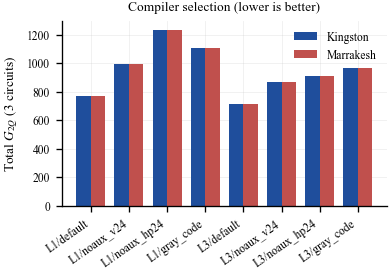

[figure] v9-results\hagcs_88_hardware\figures\F1a_compiler_selection.pdf/.png


In [5]:
# ============================================================
# STAGE 1c — COMPILER SELECTION (Section II-D): 2 opt. levels x 4 MCX plugins, per processor
# ============================================================
COMPILERS = [(lvl, plug) for lvl in (1, 3) for plug in ("default", "noaux_v24", "noaux_hp24", "gray_code")]
REP_CIRCUITS = {
    "single-target n=5 r=1": single_target_circuit(5, "10110", 1),
    "2-SAT n=5 Oracle-A r=1": ksat_circuit(5, "A", 1),
    "2-SAT n=5 Oracle-B r=1": ksat_circuit(5, "B", 1),
}

def make_pm(bname, lvl, plug):
    kw = dict(optimization_level=lvl, backend=BACKEND_OBJ[bname], seed_transpiler=SEED)
    if plug != "default":
        kw["hls_config"] = HLSConfig(mcx=[plug])
    return generate_preset_pass_manager(**kw)

comp_path = DIRS["stage1"] / "compiler_selection.csv"
if comp_path.exists():
    COMP_DF = pd.read_csv(comp_path)
else:
    rows = []
    for bname in BACKENDS:
        for lvl, plug in COMPILERS:
            pm = make_pm(bname, lvl, plug)
            row = {"backend": bname, "opt_level": lvl, "mcx_plugin": plug}
            for label, qc in REP_CIRCUITS.items():
                try:
                    row[label] = pm.run(qc).num_nonlocal_gates()
                except Exception as e:
                    row[label] = np.nan; print(f"  {bname} L{lvl} {plug} failed on {label}: {e}")
            row["total G2Q"] = sum(row[l] for l in REP_CIRCUITS)
            rows.append(row)
    COMP_DF = pd.DataFrame(rows)
    COMP_DF.to_csv(comp_path, index=False)

COMPILER = {}
for bname, g in COMP_DF.groupby("backend", sort=False):
    best = g.loc[g["total G2Q"].idxmin()]          # first minimum in listed order -> ties go to 'default'
    COMPILER[bname] = (int(best.opt_level), best.mcx_plugin)
    print(f"Selected compiler for {bname}: optimization_level={COMPILER[bname][0]}, mcx='{COMPILER[bname][1]}'")
COMP_DF["selected"] = [COMPILER[b] == (int(l), p) for b, l, p in zip(COMP_DF.backend, COMP_DF.opt_level, COMP_DF.mcx_plugin)]
save_table(COMP_DF, "T3_compiler_selection", "Two-qubit-gate count of representative circuits per compiler.")

_PM = {}
def compile_for(bname, qc):
    if bname not in _PM:
        _PM[bname] = make_pm(bname, *COMPILER[bname])
    return _PM[bname].run(qc)

# ---- figure: compiler selection ----
fig, ax = plt.subplots(figsize=(IEEE_COL, 2.0))
labels = [f"L{l}/{p}" for l, p in COMPILERS]
x = np.arange(len(labels)); w = 0.38
for i, bname in enumerate(BACKENDS):
    g = COMP_DF[COMP_DF.backend == bname]
    ax.bar(x + (i - 0.5) * w, g["total G2Q"], w, color=COL[bname], label=BK[bname])
ax.set_xticks(x); ax.set_xticklabels(labels, rotation=35, ha="right")
ax.set_ylabel(r"Total $G_{2Q}$ (3 circuits)"); ax.legend(frameon=False)
ax.set_title("Compiler selection (lower is better)")
save_fig(fig, "F1a_compiler_selection")


In [6]:
# ============================================================
# STAGE 1d — CIRCUIT DIAGRAMS (no QPU time). Logical r=1 (readable) + optional transpiled.
# ============================================================
DRAW_TRANSPILED = False   # transpiled circuits have >1000 CZ gates; diagrams are large and slow

def save_circuit_figure(qc, stem, title=None, fold=-1, scale=0.55):
    try:
        fig = qc.draw(output="mpl", fold=fold, scale=scale)
        if title:
            fig.suptitle(title, fontsize=11, y=1.02)
        fig.savefig(DIRS["circuit_diagrams"] / f"{stem}.pdf")
        fig.savefig(DIRS["circuit_diagrams"] / f"{stem}.png", dpi=300)
        plt.close(fig)
        return True
    except Exception as e:
        print(f"  diagram {stem} failed: {e}"); return False

for n in INSTANCE_N:
    for o in ORACLES:
        ok = save_circuit_figure(ksat_circuit(n, o, 1), f"logical_n{n}_oracle{o}_r1",
                                 f"2-SAT Grover circuit, n={n}, Oracle-{o}, one iteration")
    save_circuit_figure(oracle_clauses(n, KSAT[n]["clauses"]), f"oracleB_block_n{n}", f"Oracle-B, n={n}")
    save_circuit_figure(oracle_marked(n, KSAT[n]["solutions"]), f"oracleA_block_n{n}", f"Oracle-A, n={n}")

if DRAW_TRANSPILED:
    for bname in BACKENDS:
        for n, o, r in [(5, "A", 1), (5, "B", 1)]:
            save_circuit_figure(compile_for(bname, ksat_circuit(n, o, r)), f"transpiled_{bname}_n{n}_{o}_r{r}",
                                f"Transpiled, {BK[bname]}, n={n}, Oracle-{o}, r={r}", fold=40)
print("Circuit diagrams in", DIRS["circuit_diagrams"])


Circuit diagrams in v9-results\hagcs_88_hardware\circuit_diagrams


In [7]:
# ============================================================
# STAGE 1c — ORACLE CHECK, 8 CONFIGURATION RECORDS, COMPILED CIRCUITS AND OBSERVABLES
# ============================================================
def oracle_marked_set(n, o):
    """Basis states whose sign the oracle flips (exact statevector check of the circuits used)."""
    if o == "A":
        qc = QuantumCircuit(n); qc.h(range(n)); qc.compose(oracle_marked(n, KSAT[n]["solutions"]), inplace=True)
        amp = Statevector(qc).data
    else:
        ob = oracle_clauses(n, KSAT[n]["clauses"]); tot = ob.num_qubits
        qc = QuantumCircuit(tot); qc.h(range(n)); qc.x(tot - 1); qc.h(tot - 1); qc.compose(ob, inplace=True)
        amp = Statevector(qc).data          # ancillas |0>, output |-> : sign of the out=0 component
    return sorted(format(i, f"0{n}b") for i in range(2 ** n) if amp[i].real < 0)

rows = []
for n in SAT_N:
    enum = sorted(format(i, f"0{n}b") for i in range(2 ** n) if satisfies(format(i, f"0{n}b"), KSAT[n]["clauses"]))
    for o in ORACLES:
        mk = oracle_marked_set(n, o)
        rows.append({"n": n, "oracle": o, "marked_by_oracle": ", ".join(mk), "satisfying_assignments": ", ".join(enum),
                     "ok": mk == enum == sorted(KSAT[n]["solutions"])})
ORACLE_CHECK = pd.DataFrame(rows); display(ORACLE_CHECK)
assert ORACLE_CHECK.ok.all(), "An oracle does not mark exactly the satisfying assignments!"

def solution_projectors(n, total_qubits):
    """[Pi_S, Pi_s1, Pi_s2, Pi_s3] on the n variable qubits (indices 0..n-1) of the full circuit (Eq. 6)."""
    def proj(sols):
        terms = []
        for s in sols:
            bits = [int(c) for c in reversed(s)]
            for mask in range(2 ** n):
                idx = [i for i in range(n) if (mask >> i) & 1]
                terms.append(("Z" * len(idx), idx, float(np.prod([(-1) ** bits[i] for i in idx])) / 2 ** n))
        return SparsePauliOp.from_sparse_list(terms, num_qubits=total_qubits).simplify()
    S = KSAT[n]["solutions"]
    return [proj(S)] + [proj([s]) for s in S]

for n in SAT_N:                          # the observable reproduces P_ideal exactly, for both oracles
    for o in ORACLES:
        qc = ksat_circuit(n, o, 1, measure=False)
        assert abs(Statevector(qc).expectation_value(solution_projectors(n, qc.num_qubits)[0]).real
                   - p_ideal_theory(n, 1)) < 1e-9

# ---- logical resources and the 8 configuration records ----
rec, TQ, OBS, phys = [], {}, {}, []
for (n, o, r) in CONFIGS:
    qc = ksat_circuit(n, o, r, measure=False)
    lg = transpile(qc, basis_gates=["cz", "rz", "sx", "x"], optimization_level=3, seed_transpiler=SEED)
    rec.append({"ID": CID[(n, o, r)], "n": n, "N": 2 ** n, "oracle": o, "r": r, "m_clauses": len(KSAT[n]["clauses"]),
                "satisfying_assignments": ", ".join(KSAT[n]["solutions"]), "M": len(KSAT[n]["solutions"]),
                "qubits": qc.num_qubits, "logical_2Q_gates": lg.num_nonlocal_gates(), "logical_depth": lg.depth(),
                "P_ideal": p_ideal_theory(n, r), "P_rand": p_rand(n), "r_star": r_star(n)})
    for b in PROCESSORS:
        tq = compile_for(b, qc)
        TQ[(b, n, o, r)] = tq
        OBS[(b, n, o, r)] = [p.apply_layout(tq.layout) for p in solution_projectors(n, qc.num_qubits)]
        phys.append({"ID": CID[(n, o, r)], "backend": b, "n": n, "oracle": o, "r": r, "physical_2Q_gates": tq.num_nonlocal_gates(),
                     "physical_depth": tq.depth(), "total_gates": tq.size(), "duration_us": circuit_duration(b, tq) * 1e6})
STAGE1 = pd.DataFrame(rec)
PHYS = pd.DataFrame(phys)
save_table(STAGE1, "S1_configuration_records", "Stage 1: the eight configuration records C1--C8.",
           latex_cols=["ID", "n", "N", "oracle", "r", "qubits", "logical_2Q_gates", "logical_depth", "P_ideal", "P_rand"])
save_table(PHYS, "S1b_compiled_resources", "Compiled resources of C1--C8 on each processor.")
print(f"Stage 1: {len(STAGE1)} configuration records.")


,n,oracle,marked_by_oracle,satisfying_assignments,ok
0,5,A,"00000, 01010, 11111","00000, 01010, 11111",True
1,5,B,"00000, 01010, 11111","00000, 01010, 11111",True
2,6,A,"000000, 101010, 111111","000000, 101010, 111111",True
3,6,B,"000000, 101010, 111111","000000, 101010, 111111",True


,ID,n,N,oracle,r,m_clauses,satisfying_assignments,M,qubits,logical_2Q_gates,logical_depth,P_ideal,P_rand,r_star
0,C1,5,32,A,5,6,"00000, 01010, 11111",3,5,720,2590,0.077136,0.093750,2
1,C2,5,32,A,6,6,"00000, 01010, 11111",3,5,864,3107,0.617301,0.093750,2
2,C3,5,32,B,5,6,"00000, 01010, 11111",3,12,700,2088,0.077136,0.093750,2
3,C4,5,32,B,6,6,"00000, 01010, 11111",3,12,840,2505,0.617301,0.093750,2
4,C5,6,64,A,5,7,"000000, 101010, 111111",3,6,1642,5381,0.455673,0.046875,3
5,C6,6,64,A,6,7,"000000, 101010, 111111",3,6,1970,6455,0.089915,0.046875,3
6,C7,6,64,B,5,7,"000000, 101010, 111111",3,14,840,2408,0.455673,0.046875,3
7,C8,6,64,B,6,7,"000000, 101010, 111111",3,14,1008,2889,0.089915,0.046875,3


[table] v9-results\hagcs_88_hardware\tables\S1_configuration_records.csv/.tex


,ID,backend,n,oracle,r,physical_2Q_gates,physical_depth,total_gates,duration_us
0,C1,ibm_kingston,5,A,5,1297,3596,5666,122.980
1,C1,ibm_marrakesh,5,A,5,1297,3580,5691,128.724
2,C2,ibm_kingston,5,A,6,1557,4315,6797,147.604
3,C2,ibm_marrakesh,5,A,6,1557,4295,6827,154.488
4,C3,ibm_kingston,5,B,5,1791,3626,7249,128.124
5,C3,ibm_marrakesh,5,B,5,1791,3634,7255,136.656
6,C4,ibm_kingston,5,B,6,2072,4169,8557,145.008
7,C4,ibm_marrakesh,5,B,6,2072,4180,8571,154.036
8,C5,ibm_kingston,6,A,5,2687,8751,12173,287.668
9,C5,ibm_marrakesh,6,A,5,2687,8684,12012,300.788


[table] v9-results\hagcs_88_hardware\tables\S1b_compiled_resources.csv/.tex
Stage 1: 8 configuration records.


---
## Stage 2 — Ideal / noiseless reference (8 results)

Each configuration C1–C8 is (i) evaluated exactly by statevector and checked against Eq. (3) to $10^{-6}$, and (ii) sampled on the noiseless Aer simulator. These eight results are the reference for every hardware cell; they are never treated as a mitigation method and no noisy simulator is used.


Eq. (3) check: max |P_sv - P_eq3| = 1.9e-13 over 36 circuits (both oracles identical).


,ID,source,method,n,oracle,r,shots,P_ideal,P_ideal_statevector,P_valid,sigma_P,expected_shots,hellinger_vs_exact,within_4sigma_of_eq3,P_solution[00000],P_solution[01010],P_solution[11111],P_solution[000000],P_solution[101010],P_solution[111111]
0,C1,Ideal simulator,IDEAL,5,A,5,2000,0.077136,0.077136,0.0800,0.006066,12.500000,0.995609,True,0.0310,0.0255,0.0235,NaN,NaN,NaN
1,C2,Ideal simulator,IDEAL,5,A,6,2000,0.617301,0.617301,0.6120,0.010896,1.633987,0.996373,True,0.1955,0.2090,0.2075,NaN,NaN,NaN
2,C3,Ideal simulator,IDEAL,5,B,5,2000,0.077136,0.077136,0.0825,0.006152,12.121212,0.995613,True,0.0310,0.0275,0.0240,NaN,NaN,NaN
3,C4,Ideal simulator,IDEAL,5,B,6,2000,0.617301,0.617301,0.6095,0.010909,1.640689,0.996579,True,0.2085,0.1865,0.2145,NaN,NaN,NaN
4,C5,Ideal simulator,IDEAL,6,A,5,2000,0.455673,0.455673,0.4635,0.011151,2.157497,0.991894,True,NaN,NaN,NaN,0.1475,0.164,0.1520
5,C6,Ideal simulator,IDEAL,6,A,6,2000,0.089915,0.089915,0.0950,0.006556,10.526316,0.991989,True,NaN,NaN,NaN,0.0350,0.031,0.0290
6,C7,Ideal simulator,IDEAL,6,B,5,2000,0.455673,0.455673,0.4710,0.011162,2.123142,0.993052,True,NaN,NaN,NaN,0.1555,0.156,0.1595
7,C8,Ideal simulator,IDEAL,6,B,6,2000,0.089915,0.089915,0.0930,0.006494,10.752688,0.993218,True,NaN,NaN,NaN,0.0360,0.029,0.0280


[table] v9-results\hagcs_88_hardware\tables\S2_ideal_results.csv/.tex
Stage 2: 8 ideal results, all consistent with Eq. (3).


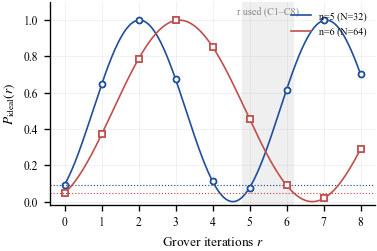

[figure] v9-results\hagcs_88_hardware\figures\F2_ideal_P_vs_r.pdf/.png


In [8]:
# ============================================================
# STAGE 2 — IDEAL / NOISELESS REFERENCE (8 results)
# ============================================================
def counts_to_vec(counts, n):
    v = np.zeros(2 ** n)
    for k, c in counts.items():
        v[int(k.replace(" ", "")[-n:], 2)] += c
    return v

def p_of(vec, sols):
    return vec[[int(s, 2) for s in sols]].sum() / vec.sum()

_IDEAL_DIST = {}
def ideal_dist(n, o, r):
    if (n, o, r) not in _IDEAL_DIST:
        _IDEAL_DIST[(n, o, r)] = ideal_distribution(ksat_circuit(n, o, r, measure=False), n)
    return _IDEAL_DIST[(n, o, r)]

# (i) exact check of Eq. (3) for both oracles over r = 0..8 (curve for the paper)
sv = [{"n": n, "oracle": o, "r": r, "P_sv": sum(ideal_dist(n, o, r).get(s, 0.0) for s in KSAT[n]["solutions"]),
       "P_eq3": p_ideal_theory(n, r)} for n in SAT_N for o in ORACLES for r in range(9)]
SV = pd.DataFrame(sv); SV["abs_dev"] = (SV.P_sv - SV.P_eq3).abs()
assert SV.abs_dev.max() < 1e-6, "statevector deviates from Eq. (3)"
SV.to_csv(DIRS["stage2"] / "statevector_vs_eq3_r0-8.csv", index=False)
print(f"Eq. (3) check: max |P_sv - P_eq3| = {SV.abs_dev.max():.1e} over {len(SV)} circuits (both oracles identical).")

# (ii) noiseless sampler for the 8 configurations
_sim = AerSimulator(method="statevector", seed_simulator=SEED)
rows = []
for (n, o, r) in CONFIGS:
    S = KSAT[n]["solutions"]
    tq = transpile(ksat_circuit(n, o, r, measure=True), _sim, optimization_level=0)
    counts = {k.replace(" ", ""): int(v) for k, v in _sim.run(tq, shots=IDEAL_SHOTS, seed_simulator=SEED).result().get_counts().items()}
    vec = counts_to_vec(counts, n); Ns = vec.sum(); P = p_of(vec, S)
    exact = ideal_dist(n, o, r); P_eq3 = p_ideal_theory(n, r)
    row = {"ID": CID[(n, o, r)], "source": "Ideal simulator", "method": "IDEAL", "n": n, "oracle": o, "r": r,
           "shots": int(Ns), "P_ideal": P_eq3, "P_ideal_statevector": sum(exact.get(s, 0.0) for s in S),
           "P_valid": P, "sigma_P": np.sqrt(P * (1 - P) / Ns), "expected_shots": 1 / P if P > 0 else np.nan,
           "hellinger_vs_exact": hellinger_fidelity({format(i, f"0{n}b"): x for i, x in enumerate(vec) if x > 0},
                                                    {k: v for k, v in exact.items() if v > 1e-12}),
           "within_4sigma_of_eq3": abs(P - P_eq3) <= 4 * np.sqrt(P_eq3 * (1 - P_eq3) / Ns) + 1e-12,
           "counts_json": json.dumps(counts)}
    for s in S:
        row[f"P_solution[{s}]"] = vec[int(s, 2)] / Ns
    rows.append(row)
IDEAL_RESULTS_DF = pd.DataFrame(rows)
save_table(IDEAL_RESULTS_DF, "S2_ideal_results", "Stage 2: ideal (noiseless) reference for C1--C8.",
           latex_cols=["ID", "n", "oracle", "r", "P_ideal", "P_valid", "sigma_P", "expected_shots"])
assert IDEAL_RESULTS_DF.within_4sigma_of_eq3.all(), "noiseless sampler disagrees with Eq. (3)"
print(f"Stage 2: {len(IDEAL_RESULTS_DF)} ideal results, all consistent with Eq. (3).")

# figure: ideal P(r) with the 8 configurations marked
fig, ax = plt.subplots(figsize=(IEEE_COL, 2.2))
rr = np.linspace(0, 8, 400)
for n, c in zip(SAT_N, [COL["ibm_kingston"], COL["ibm_marrakesh"]]):
    ax.plot(rr, np.sin((2 * rr + 1) * np.arcsin(np.sqrt(3 / 2 ** n))) ** 2, color=c, lw=1, label=f"n={n} (N={2 ** n})")
    for o, fill in [("A", c), ("B", "white")]:
        d = SV[(SV.n == n) & (SV.oracle == o)]
        ax.plot(d.r, d.P_sv, "o" if n == 5 else "s", color=c, mfc=fill, ms=3.5, ls="")
    ax.axhline(p_rand(n), color=c, ls=":", lw=0.7)
ax.axvspan(min(ITERATIONS) - 0.2, max(ITERATIONS) + 0.2, color="grey", alpha=0.12, lw=0)
ax.text(np.mean(ITERATIONS), 1.03, "r used (C1–C8)", ha="center", fontsize=6, color="grey")
ax.set_xlabel("Grover iterations $r$"); ax.set_ylabel(r"$P_{\rm ideal}(r)$"); ax.set_ylim(-0.02, 1.1)
ax.legend(fontsize=6, frameon=False, loc="upper right")
save_fig(fig, "F2_ideal_P_vs_r")


---
## Stage 3 — RAW hardware (16 results) · Stage 4 — Error mitigation (64 results)

Each of C1–C8 is run on both processors with the compiler of Stage 1. All 80 hardware cells use the Runtime Estimator with the solution projector of Eq. (6), 2000 shots, two repetitions, so RAW and the four techniques differ only in the Runtime setting (Table 3): RAW = resilience level 0; DD = XX dynamical decoupling; PT/Twirling = gate twirling, 16 randomizations; ZNE = gate folding (1, 3, 5) with exponential/linear extrapolation; TREX = measurement twirling with readout mitigation. One job per (method, processor) holds all eight configurations, so the cells of a job share one calibration window.


In [9]:
# ============================================================
# STAGE 3a — CALIBRATION SNAPSHOT (median errors, T1, T2) at execution time
# ============================================================
def calibration_snapshot(bname):
    t = BACKEND_OBJ[bname].target
    def errs(op):
        if op not in t.operation_names:
            return np.array([])
        return np.array([p.error for p in t[op].values() if p is not None and p.error is not None])
    two_q = next((g for g in ("cz", "ecr", "cx") if g in t.operation_names), None)
    t1 = np.array([q.t1 for q in t.qubit_properties if q is not None and q.t1]) if t.qubit_properties else np.array([])
    t2 = np.array([q.t2 for q in t.qubit_properties if q is not None and q.t2]) if t.qubit_properties else np.array([])
    return {"backend": bname, "qubits": t.num_qubits, "2Q gate": two_q,
            "median 2Q error": np.median(errs(two_q)), "median SX error": np.median(errs("sx")),
            "median readout error": np.median(errs("measure")),
            "median T1 (us)": np.median(t1) * 1e6 if t1.size else np.nan,
            "median T2 (us)": np.median(t2) * 1e6 if t2.size else np.nan,
            "rep delay (us)": rep_delay(bname) * 1e6, "snapshot": str(dt.datetime.now())}

cal_path = DIRS["stage3"] / "calibration_snapshot.csv"
if cal_path.exists():
    TAB6 = pd.read_csv(cal_path)
else:
    TAB6 = pd.DataFrame([calibration_snapshot(b) for b in BACKENDS]); TAB6.to_csv(cal_path, index=False)
CAL = TAB6.set_index("backend")
save_table(TAB6, "T6_calibration", "Processor calibration snapshot (medians over the device).")


,backend,qubits,2Q gate,median 2Q error,median SX error,median readout error,median T1 (us),median T2 (us),rep delay (us),snapshot
0,ibm_kingston,156,cz,0.001995,0.000303,0.009033,233.959211,145.364960,250.0,2026-10-09 11:34:39.572307
1,ibm_marrakesh,156,cz,0.002814,0.000394,0.017456,150.389273,80.701144,250.0,2026-10-09 11:34:39.572307


[table] v9-results\hagcs_88_hardware\tables\T6_calibration.csv/.tex


In [10]:
# ============================================================
# STAGE 3/4 — SHARED EXECUTION: Table-3 settings, one Estimator job per (method, processor), cost estimate
# ============================================================
def estimator_options(strategy):
    o = {"default_shots": SHOTS, "resilience_level": 0,
         "dynamical_decoupling": {"enable": False},
         "twirling": {"enable_gates": False, "enable_measure": False},
         "resilience": {"measure_mitigation": False, "zne_mitigation": False}}
    if strategy in ("DD", "all"):
        o["dynamical_decoupling"] = {"enable": True, "sequence_type": "XX"}
    if strategy in ("PT", "all"):
        o["twirling"].update({"enable_gates": True, "num_randomizations": 16})
    if strategy in ("TREX", "all"):
        o["twirling"]["enable_measure"] = True
        o["resilience"]["measure_mitigation"] = True
    if strategy in ("ZNE", "all"):
        o["resilience"]["zne_mitigation"] = True
        o["resilience"]["zne"] = {"noise_factors": (1, 3, 5), "extrapolator": ("exponential", "linear"),
                                  "amplifier": "gate_folding"}
    return o


JOB_OUT = {}   # (method, backend) -> run_cached output, or {"missing_reason": ...}

def job_key(m):
    return f"primary_{m}_r{'-'.join(map(str, ITERATIONS))}_s{SHOTS}x{REPS}"

def job_pubs(b):
    return [(TQ[(b, *c)], OBS[(b, *c)]) for _ in range(REPS) for c in CONFIGS]

def job_estimate(b, m):
    return estimate_qpu_s(b, [p[0] for p in job_pubs(b)], SHOTS, multiplier=BUDGET_MULT[m])

def run_method(m, stage):
    for b in PROCESSORS:
        est = job_estimate(b, m)
        opts = estimator_options(METHOD_TO_V7[m]); opts["default_shots"] = SHOTS
        print(f"[{stage}] {LBL[m]} @ {LBL[b]}  (estimate {est:.1f} s)")
        cached = (DIRS["cache"] / f"{job_key(m)}__{b}.json").exists() or LEDGER.find(job_key(m), b) is not None
        if RUN_MODE == "hardware" and not cached and LEDGER.spent() + est > GLOBAL_CAP_S - STAGE6_RESERVE_S:
            why = f"QPU budget: {LEDGER.spent():.0f} s used + {est:.0f} s estimate > {GLOBAL_CAP_S - STAGE6_RESERVE_S:.0f} s (Stage-6 reserve kept)"
            print("  [not submitted]", why); RUN_STATUS[(job_key(m), b)] = why
            JOB_OUT[(m, b)] = {"missing_reason": why, "est_s": est}; continue
        out = run_cached(job_key(m), b, "estimator", job_pubs(b), stage, options=opts, est_s=est)
        if out is None or "evs_all" not in out:
            out = {"missing_reason": RUN_STATUS.get((job_key(m), b), "not run" if out is None
                                                    else "cached result lacks per-observable values"), "est_s": est}
        else:
            out["est_s"] = est
        JOB_OUT[(m, b)] = out

COST = pd.DataFrame([{"stage": "3" if m == "RAW" else "4", "method": LBL[m], "backend": LBL[b], "circuits": len(CONFIGS) * REPS,
                      "estimated_QPU_s": job_estimate(b, m)} for m in METHODS for b in PROCESSORS])
COST["cumulative_s"] = COST.estimated_QPU_s.cumsum()
display(COST.round(1))
_rem = instance_remaining_s()
print(f"Estimated QPU time for the 80 hardware cells: {COST.estimated_QPU_s.sum():.0f} s | cap {GLOBAL_CAP_S:.0f} s"
      + (f" | instance remaining {_rem:.0f} s" if _rem is not None else ""))
if COST.estimated_QPU_s.sum() + STAGE6_RESERVE_S > (min(GLOBAL_CAP_S, _rem) if _rem is not None else GLOBAL_CAP_S):
    print("!!! The estimate does not fit the available time: some cells may be MISSING after this run. They are "
          "submitted automatically when the notebook is re-run with more QPU time (finished jobs are never repeated).")
else:
    print("The full 80-cell matrix fits the available QPU time.")


,stage,method,backend,circuits,estimated_QPU_s,cumulative_s
0,3,RAW,Kingston,16,17.1,17.1
1,3,RAW,Marrakesh,16,17.5,34.6
2,4,DD,Kingston,16,17.1,51.7
3,4,DD,Marrakesh,16,17.5,69.2
4,4,PT/Twirling,Kingston,16,18.6,87.8
5,4,PT/Twirling,Marrakesh,16,18.9,106.7
6,4,ZNE,Kingston,16,38.4,145.0
7,4,ZNE,Marrakesh,16,39.2,184.2
8,4,TREX,Kingston,16,20.0,204.2
9,4,TREX,Marrakesh,16,20.4,224.5


Estimated QPU time for the 80 hardware cells: 225 s | cap 590 s | instance remaining 575 s
The full 80-cell matrix fits the available QPU time.


In [11]:
# ============================================================
# STAGE 3 — RAW HARDWARE (16 results: 2 processors x 8 configurations)
# ============================================================
run_method("RAW", "stage3")


[stage3] RAW @ Kingston  (estimate 17.1 s)
  budget check [stage3]: spent on this instance 0.0s (stage) / 0.0s (total), estimate 17.1s, instance remaining 575s -> OK
  submitted primary_RAW_r5-6_s2000x2 @ ibm_kingston: job db48m0cvf2bc73cu8jcg (16 pubs, est 17.1s)
  job db48m0cvf2bc73cu8jcg: QUEUED ... waiting (timeout 1800s)
  job db48m0cvf2bc73cu8jcg: RUNNING ... waiting (timeout 1800s)
[stage3] RAW @ Marrakesh  (estimate 17.5 s)
  budget check [stage3]: spent on this instance 17.0s (stage) / 17.0s (total), estimate 17.5s, instance remaining 558s -> OK
  submitted primary_RAW_r5-6_s2000x2 @ ibm_marrakesh: job db48s2slf4us73c2ddq0 (16 pubs, est 17.5s)
  job db48s2slf4us73c2ddq0: QUEUED ... waiting (timeout 1800s)
  job db48s2slf4us73c2ddq0: RUNNING ... waiting (timeout 1800s)


### Stage 4 — Four error-management techniques (64 results: 2 processors × 8 configurations × 4 methods)


In [12]:
# ============================================================
# STAGE 4 — DD, PT/TWIRLING, ZNE, TREX (64 results)
# ============================================================
for m in MITIGATION_METHODS:
    run_method(m, "stage4")
done = sum(1 for v in JOB_OUT.values() if "evs_all" in v)
print(f"\nEstimator jobs completed: {done} of {len(JOB_OUT)}")


[stage4] DD @ Kingston  (estimate 17.1 s)
  budget check [stage4]: spent on this instance 0.0s (stage) / 34.0s (total), estimate 17.1s, instance remaining 541s -> OK
  submitted primary_DD_r5-6_s2000x2 @ ibm_kingston: job db48sf2mb58s7388s0ug (16 pubs, est 17.1s)
  job db48sf2mb58s7388s0ug: QUEUED ... waiting (timeout 1800s)
  job db48sf2mb58s7388s0ug: RUNNING ... waiting (timeout 1800s)
[stage4] DD @ Marrakesh  (estimate 17.5 s)
  budget check [stage4]: spent on this instance 17.0s (stage) / 51.0s (total), estimate 17.5s, instance remaining 524s -> OK
  submitted primary_DD_r5-6_s2000x2 @ ibm_marrakesh: job db48t6imb58s7388s1tg (16 pubs, est 17.5s)
  job db48t6imb58s7388s1tg: QUEUED ... waiting (timeout 1800s)
  job db48t6imb58s7388s1tg: RUNNING ... waiting (timeout 1800s)
[stage4] PT/Twirling @ Kingston  (estimate 18.6 s)
  budget check [stage4]: spent on this instance 34.0s (stage) / 68.0s (total), estimate 18.6s, instance remaining 507s -> OK
  submitted primary_TWIRLING_r5-6_s2000

In [13]:
# ============================================================
# STAGES 3-4 — MASTER HARDWARE MATRIX (80 rows: processor x configuration x method), full precision
# ============================================================
IDEAL_P = {(x.n, x.oracle, x.r): x.P_ideal for x in IDEAL_RESULTS_DF.itertuples()}
rows = []
for m in METHODS:
    for b in PROCESSORS:
        out = JOB_OUT.get((m, b)) or {}
        ok = "evs_all" in out
        q = out.get("quantum_seconds") if ok else None
        q_ok = q is not None and np.isfinite(q) and q > 0
        Q_circ = ((q if q_ok else out.get("est_s", np.nan)) / out["n_pubs"]) if ok else np.nan
        for j, (n, o, r) in enumerate(CONFIGS):
            S = KSAT[n]["solutions"]; tq = TQ[(b, n, o, r)]
            row = {"ID": CID[(n, o, r)], "stage": 3 if m == "RAW" else 4, "backend": b, "n": n, "oracle": o, "r": r,
                   "method": m, "method_class": METHOD_CLASS[m], "runtime_setting": METHOD_TO_V7[m], "data_source": DATA_SOURCE,
                   "shots": SHOTS * REPS if ok else np.nan, "repetitions": REPS, "P_ideal": IDEAL_P[(n, o, r)],
                   "P_rand": p_rand(n), "physical_2Q_gates": tq.num_nonlocal_gates(), "physical_depth": tq.depth(),
                   "total_gates": tq.size(), "nominal_execution_multiplier": EXEC_MULT[m],
                   "status": "OK" if ok else "MISSING", "missing_reason": "" if ok else out.get("missing_reason", "not run")}
            if ok:
                idx = [rep * len(CONFIGS) + j for rep in range(REPS)]
                ev = np.array([out["evs_all"][i] for i in idx]); sd = np.array([out["stds_all"][i] for i in idx])
                P = ev[:, 0].mean()
                row.update({"P_valid": P, "sigma_P": np.sqrt(np.mean(sd[:, 0] ** 2) / REPS),
                            "P_valid_rep_spread": ev[:, 0].std(ddof=1) if REPS > 1 else np.nan,
                            "outside_0_1": bool(P < 0 or P > 1), "Q_per_circuit_s": Q_circ,
                            "Q_source": "measured" if q_ok else "estimated", "job_id": out["job_id"]})
                for k, s in enumerate(S):
                    row[f"P_solution[{s}]"] = ev[:, 1 + k].mean()
            else:
                row.update({"P_valid": np.nan, "sigma_P": np.nan, "Q_per_circuit_s": np.nan, "job_id": "NA", "outside_0_1": np.nan})
            rows.append(row)
F = pd.DataFrame(rows)

# methodology quantities (Section II-G/H), computed at full precision
F["CI95_low"], F["CI95_high"] = F.P_valid - 1.96 * F.sigma_P, F.P_valid + 1.96 * F.sigma_P
F["expected_shots"] = np.where(F.P_valid > 0, 1 / F.P_valid, np.nan)                         # T_TTS
F["relative_to_ideal"] = F.P_valid / F.P_ideal
F["absolute_error"] = (F.P_valid - F.P_ideal).abs()
F["z_vs_random"] = (F.P_valid - F.P_rand) / F.sigma_P
F["above_random (z>=1.96)"] = (F.z_vs_random >= 1.96).where(F.P_valid.notna())
raw = F[F.method == "RAW"].set_index(["backend", "n", "oracle", "r"])
key = list(zip(F.backend, F.n, F.oracle, F.r))
P_raw = np.array([raw.P_valid.get(k, np.nan) for k in key], dtype=float)
AE_raw = np.array([raw.absolute_error.get(k, np.nan) for k in key], dtype=float)
Q_raw = F[F.method == "RAW"].groupby("backend").Q_per_circuit_s.first()
with np.errstate(divide="ignore", invalid="ignore"):
    F["Gamma"] = np.where(P_raw > 0, F.P_valid / P_raw, np.nan)                                 # Eq. (7) gain
    F["kappa"] = F.Q_per_circuit_s / F.backend.map(Q_raw)                                       # Eq. (7) cost
    d_ = F.P_ideal - P_raw
    F["rho_recovery"] = np.where(np.abs(d_) > 1e-12, (F.P_valid - P_raw) / d_, np.nan)        # Eq. (8)
    F["error_reduction"] = np.where(AE_raw > 0, (AE_raw - F.absolute_error) / AE_raw, np.nan)
F["worth_cost (Gamma>kappa)"] = (F.Gamma > F.kappa).where(F.Gamma.notna() & F.kappa.notna())
F["J_robust"] = (np.maximum(0, F.P_valid - 2 * F.sigma_P) / F.physical_2Q_gates).where(F.P_valid.notna())  # Eq. (9)
FULL_RESULTS_DF = F

sol_cols = [c for c in F.columns if c.startswith("P_solution[")]
base = ["ID", "backend", "n", "oracle", "r", "status", "P_ideal", "P_valid", "sigma_P", "CI95_low", "CI95_high",
        "relative_to_ideal", "absolute_error", "expected_shots", "physical_2Q_gates", "physical_depth"]
save_table(F[F.method == "RAW"][base + sol_cols + ["missing_reason"]], "S3_raw_hardware",
           "Stage 3: RAW hardware results (16).",
           latex_cols=["ID", "backend", "P_ideal", "P_valid", "sigma_P", "relative_to_ideal", "physical_2Q_gates", "physical_depth"])
for m in MITIGATION_METHODS:
    save_table(F[F.method == m][base + ["Gamma", "kappa", "rho_recovery", "error_reduction"] + sol_cols + ["missing_reason"]],
               f"S4_{m}", f"Stage 4: {LBL[m]} results (16).",
               latex_cols=["ID", "backend", "P_valid", "sigma_P", "Gamma", "kappa", "rho_recovery"], show=False)
save_table(F[F.method != "RAW"][["ID", "backend", "n", "oracle", "r", "method", "method_class", "status", "P_valid", "sigma_P",
                                 "Gamma", "kappa", "worth_cost (Gamma>kappa)", "rho_recovery", "error_reduction",
                                 "nominal_execution_multiplier", "Q_per_circuit_s"]],
           "S4_mitigation_all", "Stage 4: all 64 error-management results: gain, cost, recovery.",
           latex_cols=["ID", "backend", "method", "P_valid", "Gamma", "kappa", "rho_recovery"], show=False)
save_table(F, "S34_full_hardware_matrix", "All 80 primary hardware results.", show=False)
print(FULL_RESULTS_DF.shape)
display(FULL_RESULTS_DF.pivot_table(index=["backend", "ID"], columns="method", values="P_valid", aggfunc="first")
        .reindex(columns=METHODS).round(4))


,ID,backend,n,oracle,r,status,P_ideal,P_valid,sigma_P,CI95_low,...,expected_shots,physical_2Q_gates,physical_depth,P_solution[00000],P_solution[01010],P_solution[11111],P_solution[000000],P_solution[101010],P_solution[111111],missing_reason
0,C1,ibm_kingston,5,A,5,OK,0.077136,0.10450,0.004607,0.095471,...,9.569378,1297,3596,0.03850,0.03525,0.03075,NaN,NaN,NaN,
1,C2,ibm_kingston,5,A,6,OK,0.617301,0.11125,0.004607,0.102220,...,8.988764,1557,4315,0.04425,0.03800,0.02900,NaN,NaN,NaN,
2,C3,ibm_kingston,5,B,5,OK,0.077136,0.10550,0.004607,0.096471,...,9.478673,1791,3626,0.04150,0.03800,0.02600,NaN,NaN,NaN,
3,C4,ibm_kingston,5,B,6,OK,0.617301,0.09500,0.004607,0.085970,...,10.526316,2072,4169,0.03600,0.03275,0.02625,NaN,NaN,NaN,
4,C5,ibm_kingston,6,A,5,OK,0.455673,0.04950,0.003341,0.042952,...,20.202020,2687,8751,NaN,NaN,NaN,0.02250,0.01400,0.01300,
5,C6,ibm_kingston,6,A,6,OK,0.089915,0.04600,0.003341,0.039452,...,21.739130,3221,10496,NaN,NaN,NaN,0.02025,0.01100,0.01475,
6,C7,ibm_kingston,6,B,5,OK,0.455673,0.04475,0.003341,0.038201,...,22.346369,2365,4297,NaN,NaN,NaN,0.02325,0.01325,0.00825,
7,C8,ibm_kingston,6,B,6,OK,0.089915,0.04925,0.003341,0.042702,...,20.304569,3026,5622,NaN,NaN,NaN,0.01925,0.01500,0.01500,
8,C1,ibm_marrakesh,5,A,5,OK,0.077136,0.09975,0.004608,0.090719,...,10.025063,1297,3580,0.02950,0.03475,0.03550,NaN,NaN,NaN,
9,C2,ibm_marrakesh,5,A,6,OK,0.617301,0.09400,0.004607,0.084970,...,10.638298,1557,4295,0.02750,0.03550,0.03100,NaN,NaN,NaN,


[table] v9-results\hagcs_88_hardware\tables\S3_raw_hardware.csv/.tex
[table] v9-results\hagcs_88_hardware\tables\S4_DD.csv/.tex
[table] v9-results\hagcs_88_hardware\tables\S4_TWIRLING.csv/.tex
[table] v9-results\hagcs_88_hardware\tables\S4_ZNE.csv/.tex
[table] v9-results\hagcs_88_hardware\tables\S4_TREX.csv/.tex
[table] v9-results\hagcs_88_hardware\tables\S4_mitigation_all.csv/.tex
[table] v9-results\hagcs_88_hardware\tables\S34_full_hardware_matrix.csv/.tex
(80, 46)


method               RAW      DD  TWIRLING     ZNE    TREX
backend       ID                                          
ibm_kingston  C1  0.1045  0.1143    0.1040  0.1063  0.1074
              C2  0.1112  0.1073    0.1017  0.1171  0.0965
              C3  0.1055  0.0942    0.0923  0.0924  0.0936
              C4  0.0950  0.0925    0.0847  0.0879  0.1043
              C5  0.0495  0.0487    0.0577  0.0547  0.0487
              C6  0.0460  0.0412    0.0415  0.0439  0.0473
              C7  0.0447  0.0402    0.0500  0.0473  0.0385
              C8  0.0493  0.0487    0.0445  0.0518  0.0515
ibm_marrakesh C1  0.0998  0.1102    0.0918  0.1006  0.0976
              C2  0.0940  0.1088    0.0908  0.1067  0.0902
              C3  0.0918  0.0930    0.0822  0.0967  0.0870
              C4  0.0970  0.0875    0.0865  0.0932  0.0962
              C5  0.0415  0.0450    0.0543  0.0490  0.0509
              C6  0.0478  0.0478    0.0500  0.0469  0.0450
              C7  0.0500  0.0455    0.0552  0.0392  0.0473
              C8  0.0497  0.0483    0.0512  0.0500  0.0515

---
## Stage 5 — HAGCS (derived results; no new experiments)

**5A — evaluation of all 80 hardware results.** For every cell: $P_{\rm valid}$, $\sigma_P$, physical two-qubit gates $G_{2Q}$, depth, $T_{\rm TTS}$, mitigation gain $\Gamma$ and cost $\kappa$ (Eq. 7), recovery $\rho$ (Eq. 8), and $J_{\rm robust}=\max(0,P_{\rm valid}-2\sigma_P)/G_{2Q}$ (Eq. 9).

**5B — selection (4 configurations).** Within each processor × $n$ group (2 × 2 = 4 groups, 20 cells each): a cell is eligible if it is RAW or its technique is worth its cost ($\Gamma>\kappa$, Section II-G); eligible cells that are not Pareto-dominated in ($P_{\rm valid}\uparrow$, $G_{2Q}\downarrow$) form the front, and the cell with the largest $J_{\rm robust}$ on the front is selected. Only primary data are used.


In [14]:
# ============================================================
# STAGE 5A — HAGCS EVALUATION OF THE 80 HARDWARE RESULTS;  5B — 4 SELECTED CONFIGURATIONS
# ============================================================
GROUP = ["backend", "n"]

def pareto_flags(P, G):
    return np.array([not np.any((P >= p) & (G <= g) & ((P > p) | (G < g))) for p, g in zip(P, G)])

E = FULL_RESULTS_DF.copy()
E["eligible (RAW or Gamma>kappa)"] = (E.status == "OK") & ((E.method == "RAW") | (E["worth_cost (Gamma>kappa)"] == True))
E["pareto"] = False; E["rank_J_in_group"] = np.nan; E["selected"] = False
for _, g in E[E["eligible (RAW or Gamma>kappa)"]].groupby(GROUP):
    E.loc[g.index, "pareto"] = pareto_flags(g.P_valid.values, g.physical_2Q_gates.values.astype(float))
    E.loc[g.index, "rank_J_in_group"] = g.J_robust.rank(ascending=False, method="min")
    front = E.loc[g.index][E.loc[g.index, "pareto"]]
    if len(front):
        E.loc[front.J_robust.idxmax(), "selected"] = True
HAGCS_EVAL = E
EVAL_COLS = ["ID", "backend", "n", "oracle", "r", "method", "status", "P_valid", "sigma_P", "physical_2Q_gates",
             "physical_depth", "expected_shots", "Gamma", "kappa", "rho_recovery", "J_robust",
             "eligible (RAW or Gamma>kappa)", "pareto", "rank_J_in_group", "selected"]
save_table(HAGCS_EVAL[EVAL_COLS].sort_values(GROUP + ["rank_J_in_group"]), "S5A_HAGCS_evaluation",
           "Stage 5A: HAGCS evaluation of all 80 hardware results (Eq. 9).",
           latex_cols=["ID", "backend", "method", "P_valid", "sigma_P", "physical_2Q_gates", "J_robust", "pareto", "selected"],
           show=False)
PARETO_DF = HAGCS_EVAL[HAGCS_EVAL.pareto][EVAL_COLS].sort_values(GROUP + ["physical_2Q_gates"])
save_table(PARETO_DF, "S5A_pareto_front", "Pareto-optimal hardware results per processor and n.",
           latex_cols=["ID", "backend", "n", "method", "P_valid", "physical_2Q_gates", "J_robust", "selected"])

# 5B: the four selections, with the highest-P_valid cell of the same group for comparison
sel_rows = []
for (b, n), g in HAGCS_EVAL[HAGCS_EVAL.status == "OK"].groupby(GROUP):
    s = g[g.selected]
    mx = g.loc[g.P_valid.idxmax()]
    if not len(s):
        sel_rows.append({"backend": b, "n": n, "status": "MISSING", "missing_reason": "no eligible measured cell in group"})
        continue
    s = s.iloc[0]
    sel_rows.append({"group": f"{LBL[b]}, n={n}", "backend": b, "n": n, "ID": s.ID, "oracle": s.oracle, "r": s.r,
                     "method": s.method, "P_valid": s.P_valid, "sigma_P": s.sigma_P, "P_ideal": s.P_ideal,
                     "physical_2Q_gates": s.physical_2Q_gates, "physical_depth": s.physical_depth,
                     "expected_shots": s.expected_shots, "Gamma": s.Gamma, "kappa": s.kappa, "J_robust": s.J_robust,
                     "z_vs_random": s.z_vs_random, "max_P_valid_cell": f"{mx.ID}/{LBL[mx.method]}",
                     "max_P_valid": mx.P_valid, "max_P_valid_2Q_gates": mx.physical_2Q_gates,
                     "2Q_reduction_vs_max_P (%)": 100 * (mx.physical_2Q_gates - s.physical_2Q_gates) / mx.physical_2Q_gates,
                     "delta_P_vs_max_P": s.P_valid - mx.P_valid, "status": "OK"})
SELECTED = pd.DataFrame(sel_rows)
save_table(SELECTED, "S5B_selected_configurations", "Stage 5B: the four HAGCS-selected configurations.",
           latex_cols=["group", "ID", "oracle", "r", "method", "P_valid", "sigma_P", "physical_2Q_gates", "J_robust",
                       "max_P_valid_cell", "max_P_valid"])

# derived comparison matrices (same data, no new experiments)
OK = HAGCS_EVAL[HAGCS_EVAL.status == "OK"]
VALS = ["P_valid", "sigma_P", "relative_to_ideal", "absolute_error", "J_robust"]
def pair_compare(factor, a, b, keys):
    A = OK[OK[factor] == a].set_index(keys)[VALS].add_suffix(f" [{a}]")
    B = OK[OK[factor] == b].set_index(keys)[VALS].add_suffix(f" [{b}]")
    out = A.join(B, how="inner").reset_index()
    out["delta_P_valid"] = out[f"P_valid [{a}]"] - out[f"P_valid [{b}]"]
    out["z"] = out.delta_P_valid / np.sqrt(out[f"sigma_P [{a}]"] ** 2 + out[f"sigma_P [{b}]"] ** 2)
    out["significant (|z|>=1.96)"] = out.z.abs() >= 1.96
    return out
PROC_CMP = pair_compare("backend", "ibm_kingston", "ibm_marrakesh", ["n", "oracle", "r", "method"])
ORACLE_CMP = pair_compare("oracle", "A", "B", ["backend", "n", "r", "method"])
ITER_CMP = pair_compare("r", ITERATIONS[0], ITERATIONS[1], ["backend", "n", "oracle", "method"])
save_table(PROC_CMP, "S5_processor_comparison", "Kingston vs Marrakesh (identical n, oracle, r, method).", show=False,
           latex_cols=["n", "oracle", "r", "method", "P_valid [ibm_kingston]", "P_valid [ibm_marrakesh]", "delta_P_valid", "z"])
save_table(ORACLE_CMP, "S5_oracle_comparison", "Oracle A vs Oracle B (identical processor, n, r, method).", show=False,
           latex_cols=["backend", "n", "r", "method", "P_valid [A]", "P_valid [B]", "delta_P_valid", "z"])
save_table(ITER_CMP, "S5_iteration_comparison", f"r={ITERATIONS[0]} vs r={ITERATIONS[1]} (identical processor, n, oracle, method).",
           show=False, latex_cols=["backend", "n", "oracle", "method", f"P_valid [{ITERATIONS[0]}]", f"P_valid [{ITERATIONS[1]}]", "delta_P_valid", "z"])
best = []
for (b, n, o, r), g in OK.groupby(["backend", "n", "oracle", "r"]):
    el = g[g["eligible (RAW or Gamma>kappa)"]]
    if len(el) and el.J_robust.notna().any():
        w = el.loc[el.J_robust.idxmax()]
        best.append({"ID": w.ID, "backend": b, "n": n, "oracle": o, "r": r, "best_method": w.method, "J_robust": w.J_robust,
                     "P_valid": w.P_valid, "Gamma": w.Gamma, "kappa": w.kappa, "eligible": ", ".join(el.method),
                     "selection_metric": "J_robust (Eq. 9) among RAW and methods with Gamma > kappa"})
BEST_METHOD = pd.DataFrame(best)
save_table(BEST_METHOD, "S5_best_method_per_configuration", "Best error-management method per processor and configuration.",
           latex_cols=["ID", "backend", "best_method", "P_valid", "Gamma", "kappa", "J_robust"], show=False)
print(f"Stage 5A: {int((HAGCS_EVAL.status == 'OK').sum())} of {len(HAGCS_EVAL)} hardware results evaluated | "
      f"Stage 5B: {int((SELECTED.get('status', pd.Series()) == 'OK').sum())} selected")


[table] v9-results\hagcs_88_hardware\tables\S5A_HAGCS_evaluation.csv/.tex


,ID,backend,n,oracle,r,method,status,P_valid,sigma_P,physical_2Q_gates,physical_depth,expected_shots,Gamma,kappa,rho_recovery,J_robust,eligible (RAW or Gamma>kappa),pareto,rank_J_in_group,selected
16,C1,ibm_kingston,5,A,5,DD,OK,0.11425,0.004607,1297,3596,8.752735,1.093301,1.000000,-0.356307,0.000081,True,True,1.0,True
38,C7,ibm_kingston,6,B,5,TWIRLING,OK,0.05000,0.002976,2365,4297,20.000000,1.117318,1.058824,0.012776,0.000019,True,True,2.0,False
36,C5,ibm_kingston,6,A,5,TWIRLING,OK,0.05775,0.003331,2687,8751,17.316017,1.166667,1.058824,0.020312,0.000019,True,True,1.0,True
24,C1,ibm_marrakesh,5,A,5,DD,OK,0.11025,0.004607,1297,3580,9.070295,1.105263,1.000000,-0.464313,0.000078,True,True,1.0,True
14,C7,ibm_marrakesh,6,B,5,RAW,OK,0.05000,0.003341,2365,4340,20.000000,1.000000,1.000000,0.000000,0.000018,True,True,1.0,True
44,C5,ibm_marrakesh,6,A,5,TWIRLING,OK,0.05425,0.003191,2687,8684,18.433180,1.307229,1.117647,0.030784,0.000018,True,True,2.0,False


[table] v9-results\hagcs_88_hardware\tables\S5A_pareto_front.csv/.tex


,group,backend,n,ID,oracle,r,method,P_valid,sigma_P,P_ideal,...,Gamma,kappa,J_robust,z_vs_random,max_P_valid_cell,max_P_valid,max_P_valid_2Q_gates,2Q_reduction_vs_max_P (%),delta_P_vs_max_P,status
0,"Kingston, n=5",ibm_kingston,5,C1,A,5,DD,0.11425,0.004607,0.077136,...,1.093301,1.000000,0.000081,4.449874,C2/ZNE,0.117057,1557,16.69878,-0.002807,OK
1,"Kingston, n=6",ibm_kingston,6,C5,A,5,TWIRLING,0.05775,0.003331,0.455673,...,1.166667,1.058824,0.000019,3.265106,C5/PT/Twirling,0.057750,2687,0.00000,0.000000,OK
2,"Marrakesh, n=5",ibm_marrakesh,5,C1,A,5,DD,0.11025,0.004607,0.077136,...,1.105263,1.000000,0.000078,3.581511,C1/DD,0.110250,1297,0.00000,0.000000,OK
3,"Marrakesh, n=6",ibm_marrakesh,6,C7,B,5,RAW,0.05000,0.003341,0.455673,...,1.000000,1.000000,0.000018,0.935289,C7/PT/Twirling,0.055250,2365,0.00000,-0.005250,OK


[table] v9-results\hagcs_88_hardware\tables\S5B_selected_configurations.csv/.tex
[table] v9-results\hagcs_88_hardware\tables\S5_processor_comparison.csv/.tex
[table] v9-results\hagcs_88_hardware\tables\S5_oracle_comparison.csv/.tex
[table] v9-results\hagcs_88_hardware\tables\S5_iteration_comparison.csv/.tex
[table] v9-results\hagcs_88_hardware\tables\S5_best_method_per_configuration.csv/.tex
Stage 5A: 80 of 80 hardware results evaluated | Stage 5B: 4 selected


---
## Stage 6 — Fresh independent validation (4 experiments, reported separately from the 88)

The four HAGCS selections are measured again in **new jobs** with the same compiled circuit and the same Runtime setting, so selection (Stage 5) and validation never share measurements. For each selection we report the fresh $P_{\rm valid}\pm\sigma_P$, its agreement with the Stage-5 value ($z_{\rm agree}$), and whether it still exceeds random guessing ($z$ vs $M/N$).


In [15]:
# ============================================================
# STAGE 6 — FRESH INDEPENDENT VALIDATION OF THE 4 HAGCS-SELECTED CONFIGURATIONS
# ============================================================
SEL_OK = SELECTED[SELECTED.status == "OK"] if len(SELECTED) else SELECTED
VAL_JOBS = {}
for (b, m), g in SEL_OK.groupby(["backend", "method"]) if len(SEL_OK) else []:
    cfgs = [(int(x.n), x.oracle, int(x.r)) for x in g.itertuples()]
    pubs = [(TQ[(b, *c)], OBS[(b, *c)]) for _ in range(VAL_REPS) for c in cfgs]
    est = estimate_qpu_s(b, [p[0] for p in pubs], VAL_SHOTS, multiplier=BUDGET_MULT[m])
    opts = estimator_options(METHOD_TO_V7[m]); opts["default_shots"] = VAL_SHOTS
    key = f"stage6_fresh_{m}_{'-'.join(CID[c] for c in cfgs)}_s{VAL_SHOTS}x{VAL_REPS}"
    print(f"[stage6] {LBL[m]} @ {LBL[b]}: {', '.join(CID[c] for c in cfgs)}  (estimate {est:.1f} s)")
    out = run_cached(key, b, "estimator", pubs, "stage6", options=opts, est_s=est)
    VAL_JOBS[(b, m)] = (cfgs, out, RUN_STATUS.get((key, b), "not run"))

rows = []
for x in SEL_OK.itertuples():
    c = (int(x.n), x.oracle, int(x.r))
    cfgs, out, why = VAL_JOBS.get((x.backend, x.method), ([], None, "not run"))
    row = {"group": x.group, "ID": x.ID, "backend": x.backend, "n": x.n, "oracle": x.oracle, "r": x.r, "method": x.method,
           "P_ideal": x.P_ideal, "P_rand": p_rand(int(x.n)), "P_valid_stage5": x.P_valid, "sigma_stage5": x.sigma_P}
    if out is not None and "evs_all" in out:
        j = cfgs.index(c)
        idx = [rep * len(cfgs) + j for rep in range(VAL_REPS)]
        ev = np.array([out["evs_all"][i][0] for i in idx]); sd = np.array([out["stds_all"][i][0] for i in idx])
        P = ev.mean(); s = np.sqrt(np.mean(sd ** 2) / VAL_REPS)
        za = (P - x.P_valid) / np.sqrt(s ** 2 + x.sigma_P ** 2)
        zr = (P - p_rand(int(x.n))) / s
        row.update({"status": "OK", "P_valid_stage6": P, "sigma_stage6": s, "delta_P": P - x.P_valid, "z_agree": za,
                    "consistent_with_stage5 (|z|<1.96)": abs(za) < 1.96, "z_vs_random": zr,
                    "p_value_vs_random (one-sided)": float(stats.norm.sf(zr)), "above_random (z>=1.96)": zr >= 1.96,
                    "relative_to_ideal": P / x.P_ideal, "job_id": out["job_id"], "quantum_seconds": out.get("quantum_seconds")})
    else:
        row.update({"status": "MISSING", "missing_reason": why, "P_valid_stage6": np.nan, "sigma_stage6": np.nan})
    rows.append(row)
VALIDATION = pd.DataFrame(rows)
save_table(VALIDATION, "S6_independent_validation",
           "Stage 6: fresh independent validation of the four HAGCS-selected configurations.",
           latex_cols=[c for c in ["group", "ID", "method", "P_valid_stage5", "P_valid_stage6", "sigma_stage6", "z_agree",
                                   "z_vs_random"] if c in VALIDATION.columns])
n_val = int((VALIDATION.status == "OK").sum()) if len(VALIDATION) else 0
print(f"Stage 6: {n_val} of {len(SEL_OK)} selections validated in fresh jobs.")


[stage6] DD @ Kingston: C1  (estimate 4.5 s)
  budget check [stage6]: spent on this instance 0.0s (stage) / 300.0s (total), estimate 4.5s, instance remaining 275s -> OK
  submitted stage6_fresh_DD_C1_s2000x2 @ ibm_kingston: job db499l04qg6s73c1rucg (2 pubs, est 4.5s)
  job db499l04qg6s73c1rucg: QUEUED ... waiting (timeout 1800s)
  job db499l04qg6s73c1rucg: RUNNING ... waiting (timeout 1800s)
[stage6] PT/Twirling @ Kingston: C5  (estimate 5.4 s)
  budget check [stage6]: spent on this instance 4.0s (stage) / 304.0s (total), estimate 5.4s, instance remaining 271s -> OK
  submitted stage6_fresh_TWIRLING_C5_s2000x2 @ ibm_kingston: job db49blqmb58s7388smqg (2 pubs, est 5.4s)
  job db49blqmb58s7388smqg: QUEUED ... waiting (timeout 1800s)
  job db49blqmb58s7388smqg: RUNNING ... waiting (timeout 1800s)
[stage6] DD @ Marrakesh: C1  (estimate 4.5 s)
  budget check [stage6]: spent on this instance 9.0s (stage) / 309.0s (total), estimate 4.5s, instance remaining 266s -> OK
  submitted stage6_fresh_

,group,ID,backend,n,oracle,r,method,P_ideal,P_rand,P_valid_stage5,...,sigma_stage6,delta_P,z_agree,consistent_with_stage5 (|z|<1.96),z_vs_random,p_value_vs_random (one-sided),above_random (z>=1.96),relative_to_ideal,job_id,quantum_seconds
0,"Kingston, n=5",C1,ibm_kingston,5,A,5,DD,0.077136,0.093750,0.11425,...,0.004605,0.00500,0.767563,True,5.536874,1.539587e-08,True,1.545972,db499l04qg6s73c1rucg,4.0
1,"Kingston, n=6",C5,ibm_kingston,6,A,5,TWIRLING,0.455673,0.046875,0.05775,...,0.003058,-0.01700,-3.759746,False,-2.002948,9.774086e-01,False,0.089428,db49blqmb58s7388smqg,5.0
2,"Marrakesh, n=5",C1,ibm_marrakesh,5,A,5,DD,0.077136,0.093750,0.11025,...,0.004608,-0.00675,-1.035957,True,2.116059,1.716990e-02,True,1.341787,db49ec4vf2bc73cu9pq0,4.0
3,"Marrakesh, n=6",C7,ibm_marrakesh,6,B,5,RAW,0.455673,0.046875,0.05000,...,0.003341,-0.00150,-0.317450,True,0.486358,3.133565e-01,False,0.106436,db49eiimb58s7388srjg,4.0


[table] v9-results\hagcs_88_hardware\tables\S6_independent_validation.csv/.tex
Stage 6: 4 of 4 selections validated in fresh jobs.


In [16]:
# ============================================================
# VALIDITY CHECKS AND STAGE-BY-STAGE ACCOUNTING
# ============================================================
chk = []
def check(i, desc, ok, detail=""):
    chk.append({"check": i, "description": desc, "result": "PASS" if ok else "FAIL", "detail": detail})
F = FULL_RESULTS_DF
check(1, "Oracle A and B mark exactly the satisfying assignments", bool(ORACLE_CHECK.ok.all()))
check(2, "Ideal results agree with Eq. (3) (statevector 1e-6; sampler within 4 sigma)",
      bool(SV.abs_dev.max() < 1e-6 and IDEAL_RESULTS_DF.within_4sigma_of_eq3.all()))
check(3, f"Iteration counts used: {ITERATIONS}", sorted(F.r.unique()) == sorted(ITERATIONS))
check(4, f"Both n included: {SAT_N}", sorted(F.n.unique()) == sorted(SAT_N))
check(5, "Both processors included", sorted(F.backend.unique()) == sorted(PROCESSORS))
check(6, "Both oracles included", sorted(F.oracle.unique()) == sorted(ORACLES))
check(7, "RAW, DD, PT/Twirling, ZNE and TREX included", sorted(F.method.unique()) == sorted(METHODS))
miss = F[F.status == "MISSING"]
check(8, "No missing cell replaced by a number", bool(miss.P_valid.isna().all()), f"{len(miss)} missing cells kept as NA")
check(9, "No hardware row labelled as ideal; no noisy simulator used", not (F.method == "IDEAL").any()
      and "noisy_sim" not in globals())
check(10, "Ideal rows are not labelled as mitigated", set(IDEAL_RESULTS_DF.method) == {"IDEAL"})
check(11, "No duplicate rows", not F.duplicated(["backend", "n", "oracle", "r", "method"]).any()
      and not IDEAL_RESULTS_DF.duplicated(["n", "oracle", "r"]).any())
check(12, "Ideal counts sum to the requested shots", bool((IDEAL_RESULTS_DF.shots == IDEAL_SHOTS).all()))
check(13, "Count-based probabilities lie in [0, 1]", bool(IDEAL_RESULTS_DF.P_valid.between(0, 1).all()))
okr = F[F.status == "OK"]
check(14, "Estimator values (incl. ZNE/TREX) kept unclipped", True,
      f"{int(okr.outside_0_1.sum()) if len(okr) else 0} estimates outside [0,1], kept as measured")
check(15, "Same solution set S for observables, ideal reference and hardware",
      all(sorted(KSAT[n]["solutions"]) == ORACLE_CHECK[ORACLE_CHECK.n == n].satisfying_assignments.iloc[0].split(", ")
          for n in SAT_N))
check(16, "Stage 6 uses only fresh jobs (no Stage 3-4 job reused)",
      not set(VALIDATION.get("job_id", pd.Series(dtype=str)).dropna()) & set(F.job_id.dropna()))
VALIDITY = pd.DataFrame(chk)
save_table(VALIDITY, "validity_checks", "Automatic validity checks.")

def cnt(df, m=None):
    d = df if m is None else df[df.method == m]
    return int((d.status == "OK").sum())
nS = len(PROCESSORS) * len(CONFIGS)
acct = [
    ("1", "Circuit / configuration characterization", len(CONFIGS), len(STAGE1)),
    ("2", "Ideal / noiseless reference", len(CONFIGS), len(IDEAL_RESULTS_DF)),
    ("3", "RAW hardware", nS, cnt(F, "RAW")),
    *[("4", LBL[m], nS, cnt(F, m)) for m in MITIGATION_METHODS],
    ("4 total", "Four mitigation methods", nS * len(MITIGATION_METHODS), cnt(F[F.method != "RAW"])),
    ("Primary hardware", "RAW + four mitigation methods", N_HW, cnt(F)),
    ("Primary experiment total", "80 hardware + 8 ideal", N_HW + len(CONFIGS), cnt(F) + len(IDEAL_RESULTS_DF)),
    ("5A", "HAGCS evaluation of the primary hardware matrix (derived)", N_HW, int((HAGCS_EVAL.status == "OK").sum())),
    ("5B", "HAGCS-selected configurations (derived)", len(PROCESSORS) * len(SAT_N), int((SELECTED.get("status") == "OK").sum())),
    ("6", "Fresh independent validation", len(PROCESSORS) * len(SAT_N), n_val),
]
coverage_report = pd.DataFrame(acct, columns=["stage", "description", "expected", "completed"])
coverage_report["missing"] = coverage_report.expected - coverage_report.completed
save_table(coverage_report, "accounting_six_stages", "Stage-by-stage accounting of the experiment.")
print(f"\nExpected hardware cells = {N_HW}\nCompleted hardware cells = {cnt(F)}\nMissing hardware cells = {N_HW - cnt(F)}\n")
print(f"Expected ideal cells = {len(CONFIGS)}\nCompleted ideal cells = {len(IDEAL_RESULTS_DF)}\n")
print(f"Primary configurations: {cnt(F) + len(IDEAL_RESULTS_DF)} of {N_HW + len(CONFIGS)}")
if len(miss):
    display(miss[["ID", "backend", "method", "missing_reason"]])


,check,description,result,detail
0,1,Oracle A and B mark exactly the satisfying ass...,PASS,
1,2,Ideal results agree with Eq. (3) (statevector ...,PASS,
2,3,"Iteration counts used: [5, 6]",PASS,
3,4,"Both n included: [5, 6]",PASS,
4,5,Both processors included,PASS,
5,6,Both oracles included,PASS,
6,7,"RAW, DD, PT/Twirling, ZNE and TREX included",PASS,
7,8,No missing cell replaced by a number,PASS,0 missing cells kept as NA
8,9,No hardware row labelled as ideal; no noisy si...,PASS,
9,10,Ideal rows are not labelled as mitigated,PASS,


[table] v9-results\hagcs_88_hardware\tables\validity_checks.csv/.tex


,stage,description,expected,completed,missing
0,1,Circuit / configuration characterization,8,8,0
1,2,Ideal / noiseless reference,8,8,0
2,3,RAW hardware,16,16,0
3,4,DD,16,16,0
4,4,PT/Twirling,16,16,0
5,4,ZNE,16,16,0
6,4,TREX,16,16,0
7,4 total,Four mitigation methods,64,64,0
8,Primary hardware,RAW + four mitigation methods,80,80,0
9,Primary experiment total,80 hardware + 8 ideal,88,88,0


[table] v9-results\hagcs_88_hardware\tables\accounting_six_stages.csv/.tex

Expected hardware cells = 80
Completed hardware cells = 80
Missing hardware cells = 0

Expected ideal cells = 8
Completed ideal cells = 8

Primary configurations: 88 of 88


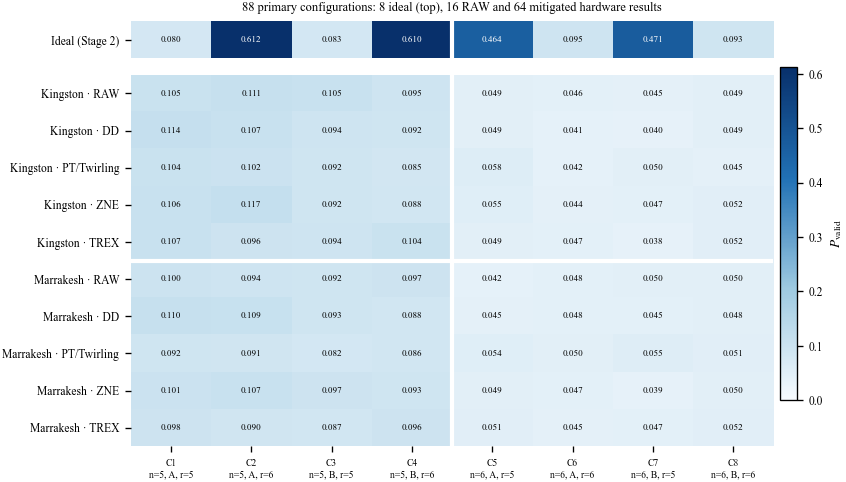

[figure] v9-results\hagcs_88_hardware\figures\FA_88_primary_configurations.pdf/.png


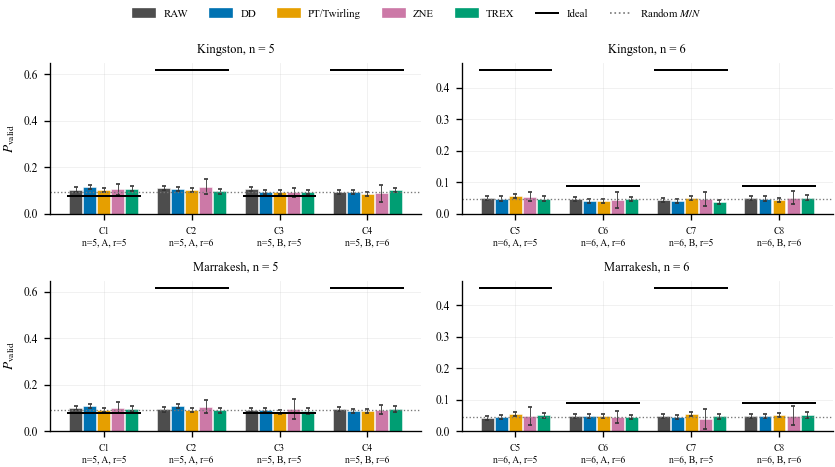

[figure] v9-results\hagcs_88_hardware\figures\FB_Pvalid_by_method.pdf/.png


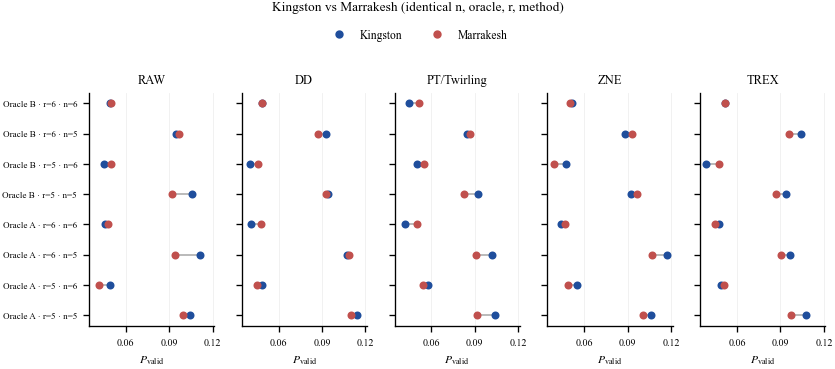

[figure] v9-results\hagcs_88_hardware\figures\FC_processor_comparison.pdf/.png


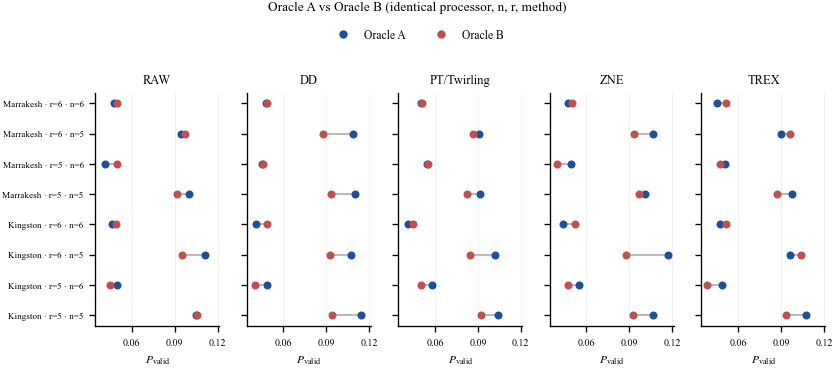

[figure] v9-results\hagcs_88_hardware\figures\FD_oracle_comparison.pdf/.png


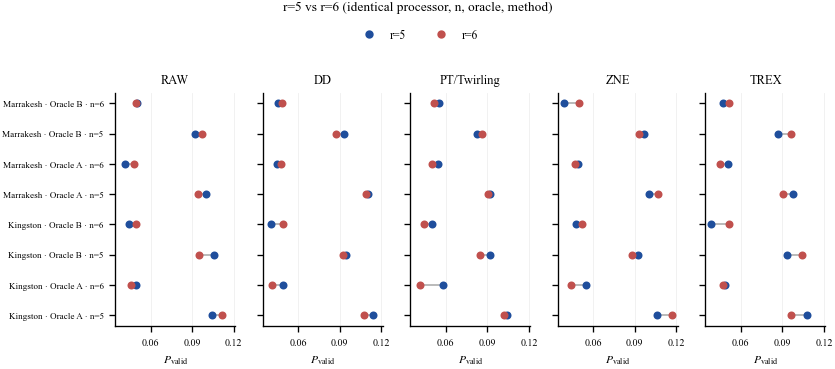

[figure] v9-results\hagcs_88_hardware\figures\FE_iteration_comparison.pdf/.png


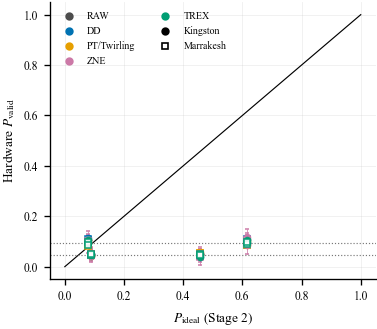

[figure] v9-results\hagcs_88_hardware\figures\FF_hardware_vs_ideal.pdf/.png


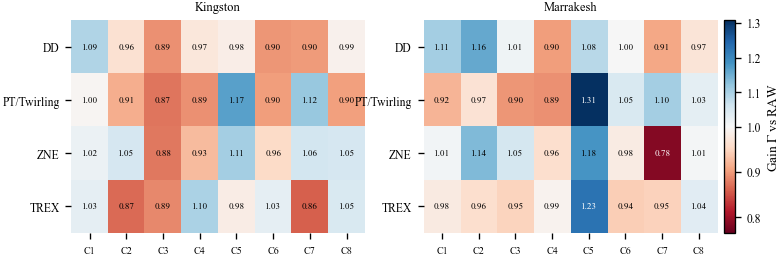

[figure] v9-results\hagcs_88_hardware\figures\FG_mitigation_gain_heatmap.pdf/.png


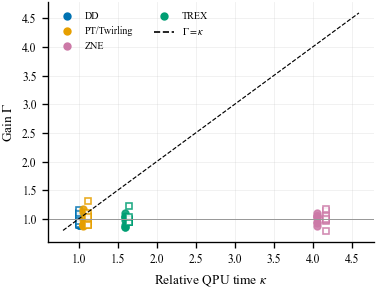

[figure] v9-results\hagcs_88_hardware\figures\FH_gain_vs_cost.pdf/.png


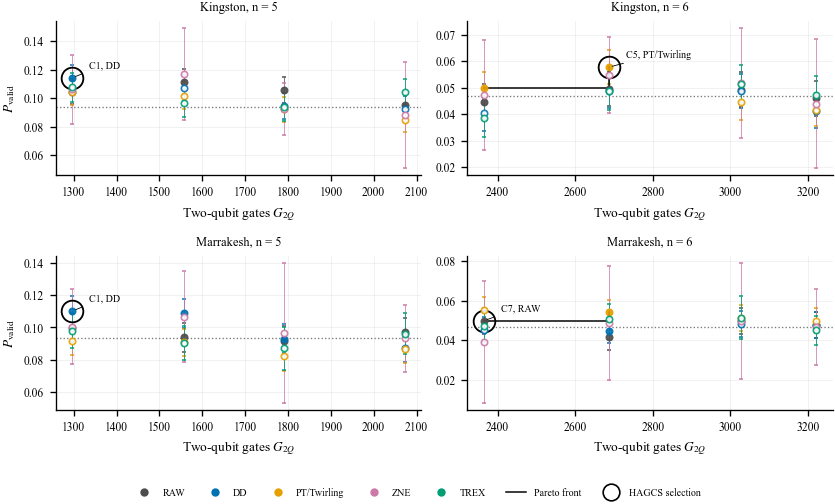

[figure] v9-results\hagcs_88_hardware\figures\FI_HAGCS_pareto_selection.pdf/.png


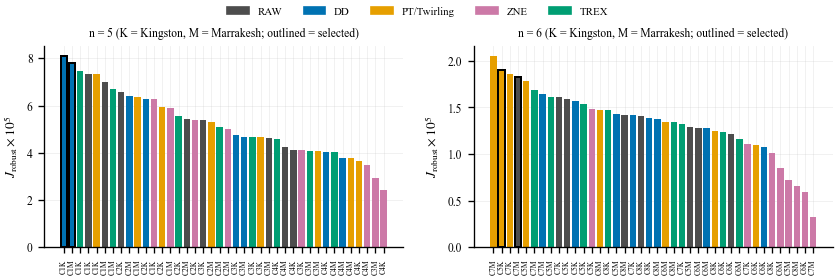

[figure] v9-results\hagcs_88_hardware\figures\FJ_HAGCS_score_all_80.pdf/.png


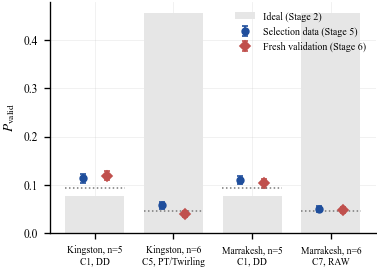

[figure] v9-results\hagcs_88_hardware\figures\FK_stage6_independent_validation.pdf/.png


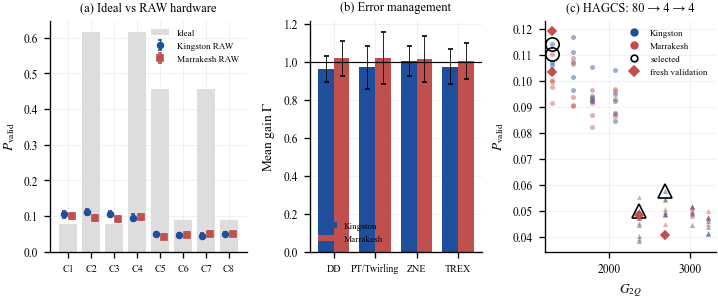

[figure] v9-results\hagcs_88_hardware\figures\FL_overview.pdf/.png
Figures in v9-results\hagcs_88_hardware\figures


In [17]:
# ============================================================
# PUBLICATION FIGURES (measured values only; no smoothing or interpolation)
# ============================================================
from matplotlib.colors import TwoSlopeNorm, LinearSegmentedColormap
from matplotlib.patches import Rectangle
from matplotlib.lines import Line2D

SEQ = LinearSegmentedColormap.from_list("hagcs", ["#F7FBFF", "#9ECAE1", "#2171B5", "#08306B"])
CLAB = lambda c: f"{CID[c]}\nn={c[0]}, {c[1]}, r={c[2]}"
F_ = FULL_RESULTS_DF.set_index(["backend", "method", "n", "oracle", "r"])
I_ = IDEAL_RESULTS_DF.set_index(["n", "oracle", "r"])
get = lambda b, m, c, col="P_valid": F_[col].get((b, m, *c), np.nan)
OKD = FULL_RESULTS_DF[FULL_RESULTS_DF.status == "OK"]
mm = MITIGATION_METHODS

def heat(ax, M, cmap, norm, fmt="{:.3f}"):
    """Annotated heatmap; NaN cells are hatched and labelled NA, never coloured as zero."""
    im = ax.imshow(np.ma.masked_invalid(M), cmap=cmap, norm=norm, aspect="auto")
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            v = M[i, j]
            if not np.isfinite(v):
                ax.add_patch(Rectangle((j - .5, i - .5), 1, 1, fill=False, hatch="////", ec="#BBBBBB", lw=0))
                ax.text(j, i, "NA", ha="center", va="center", fontsize=5.5, color="#888888")
            else:
                rgba = im.cmap(im.norm(v)); lum = 0.299 * rgba[0] + 0.587 * rgba[1] + 0.114 * rgba[2]
                ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=5.5, color="white" if lum < 0.5 else "black")
    ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)
    return im

# ---- Fig. A: the 88 primary configurations ----
ROWS = [(b, m) for b in PROCESSORS for m in METHODS]
M_hw = np.array([[get(b, m, c) for c in CONFIGS] for b, m in ROWS], dtype=float)
M_id = np.array([[I_.P_valid.get(c, np.nan) for c in CONFIGS]], dtype=float)
norm = plt.Normalize(0, max(0.05, float(np.nanmax(np.r_[M_hw.ravel(), M_id.ravel()]))))
fig, (a0, a1) = plt.subplots(2, 1, figsize=(IEEE_TXT, 4.6), gridspec_kw={"height_ratios": [1, len(ROWS)], "hspace": 0.08})
heat(a0, M_id, SEQ, norm); im = heat(a1, M_hw, SEQ, norm)
a0.set_yticks([0]); a0.set_yticklabels(["Ideal (Stage 2)"]); a0.set_xticks([])
a1.set_yticks(range(len(ROWS))); a1.set_yticklabels([f"{LBL[b]} · {LBL[m]}" for b, m in ROWS])
a1.set_xticks(range(len(CONFIGS))); a1.set_xticklabels([CLAB(c) for c in CONFIGS], fontsize=5.8)
for k in range(1, len(PROCESSORS)):
    a1.axhline(k * len(METHODS) - .5, color="white", lw=2.5)
for ax in (a0, a1):
    ax.axvline(len(CONFIGS) / 2 - .5, color="white", lw=2.5)
cb = fig.colorbar(im, ax=[a0, a1], fraction=0.025, pad=0.01); cb.set_label(r"$P_{\rm valid}$")
a0.set_title("88 primary configurations: 8 ideal (top), 16 RAW and 64 mitigated hardware results", fontsize=7.5)
save_fig(fig, "FA_88_primary_configurations")

if len(OKD):
    # ---- Fig. B: P_valid per method with ideal and random-guessing references ----
    fig, axes = plt.subplots(len(PROCESSORS), len(SAT_N), figsize=(IEEE_TXT, 3.9), sharey="col", squeeze=False)
    w = 0.8 / len(METHODS)
    for i, b in enumerate(PROCESSORS):
        for j, n in enumerate(SAT_N):
            ax = axes[i, j]; cf = [c for c in CONFIGS if c[0] == n]; x = np.arange(len(cf))
            for k, m in enumerate(METHODS):
                ax.bar(x + (k - (len(METHODS) - 1) / 2) * w, [get(b, m, c) for c in cf], w * 0.92, color=MCOL[m],
                       yerr=[1.96 * get(b, m, c, "sigma_P") for c in cf], capsize=1,
                       error_kw={"lw": 0.5, "ecolor": "#333333"}, edgecolor="white", lw=0.3)
            for xi, c in enumerate(cf):
                ax.hlines(I_.P_ideal.get(c, np.nan), xi - .42, xi + .42, color="black", lw=1.2, zorder=5)
            ax.axhline(p_rand(n), ls=":", color="#777777", lw=0.8)
            ax.set_xticks(x); ax.set_xticklabels([CLAB(c) for c in cf], fontsize=5.8)
            ax.set_title(f"{LBL[b]}, n = {n}", fontsize=7.5)
            if j == 0: ax.set_ylabel(r"$P_{\rm valid}$")
    h = [Rectangle((0, 0), 1, 1, color=MCOL[m], label=LBL[m]) for m in METHODS] + \
        [Line2D([], [], color="black", lw=1.2, label="Ideal"), Line2D([], [], color="#777777", ls=":", label="Random $M/N$")]
    fig.legend(handles=h, loc="upper center", ncol=7, fontsize=6.5, frameon=False, bbox_to_anchor=(0.5, 1.03))
    fig.tight_layout(rect=(0, 0, 1, 0.96))
    save_fig(fig, "FB_Pvalid_by_method")

    # ---- Figs. C-E: paired comparisons (processor, oracle, r) ----
    def dumbbell(factor, levels, fname, title):
        others = [k for k in ["backend", "oracle", "r", "n"] if k != factor]
        keys = sorted({tuple(row[k] for k in others) for _, row in OKD.iterrows()})
        col = {levels[0]: "#1F4E9C", levels[1]: "#C0504D"}
        fig, axes = plt.subplots(1, len(METHODS), figsize=(IEEE_TXT, 2.9), sharey=True, sharex=True, squeeze=False)
        for ax, m in zip(axes[0], METHODS):
            d = OKD[OKD.method == m].set_index(others + [factor])
            for yi, kk in enumerate(keys):
                v = [d.P_valid.get((*kk, l), np.nan) for l in levels]
                ax.plot(v, [yi, yi], "-", color="#BBBBBB", lw=1.2, zorder=1)
                for l, vv in zip(levels, v):
                    ax.plot(vv, yi, "o", color=col[l], ms=3.8, zorder=2)
            ax.set_title(LBL[m], fontsize=7.5); ax.set_xlabel(r"$P_{\rm valid}$", fontsize=7)
            ax.xaxis.set_major_locator(plt.MaxNLocator(3)); ax.tick_params(axis="x", labelsize=6); ax.grid(axis="y", alpha=0)
        lab = lambda kk: " · ".join(LBL.get(v, v) if k in ("backend", "oracle") else f"{k}={v}" for k, v in zip(others, kk))
        axes[0][0].set_yticks(range(len(keys))); axes[0][0].set_yticklabels([lab(k) for k in keys], fontsize=5.5)
        fig.legend(handles=[Line2D([], [], marker="o", ls="", color=col[l], label=(f"r={l}" if factor == "r" else LBL[l]))
                            for l in levels], loc="upper center", ncol=2, fontsize=7, frameon=False, bbox_to_anchor=(0.5, 1.04))
        fig.suptitle(title, fontsize=8, y=1.09); fig.tight_layout()
        save_fig(fig, fname)
    dumbbell("backend", PROCESSORS, "FC_processor_comparison", "Kingston vs Marrakesh (identical n, oracle, r, method)")
    dumbbell("oracle", ORACLES, "FD_oracle_comparison", "Oracle A vs Oracle B (identical processor, n, r, method)")
    dumbbell("r", ITERATIONS, "FE_iteration_comparison", f"r={ITERATIONS[0]} vs r={ITERATIONS[1]} (identical processor, n, oracle, method)")

    # ---- Fig. F: hardware against the ideal reference ----
    fig, ax = plt.subplots(figsize=(IEEE_COL, 3.0))
    for m in METHODS:
        for b in PROCESSORS:
            d = OKD[(OKD.method == m) & (OKD.backend == b)]
            ax.errorbar(d.P_ideal, d.P_valid, yerr=1.96 * d.sigma_P, fmt=PMK[b], ms=3.5, color=MCOL[m],
                        mfc=MCOL[m] if b == "ibm_kingston" else "white", lw=0.5, capsize=1, alpha=0.9)
    ax.plot([0, 1], [0, 1], "k-", lw=0.7)
    for n in SAT_N:
        ax.axhline(p_rand(n), ls=":", lw=0.7, color="#777777")
    ax.set_xlabel(r"$P_{\rm ideal}$ (Stage 2)"); ax.set_ylabel(r"Hardware $P_{\rm valid}$")
    ax.legend(handles=[Line2D([], [], marker="o", ls="", color=MCOL[m], label=LBL[m]) for m in METHODS] +
              [Line2D([], [], marker="o", ls="", color="k", label="Kingston"),
               Line2D([], [], marker="s", ls="", color="k", mfc="white", label="Marrakesh")],
              fontsize=6, frameon=False, ncol=2, loc="upper left")
    save_fig(fig, "FF_hardware_vs_ideal")

    # ---- Fig. G: mitigation gain heatmap (diverging at Gamma = 1) ----
    G_all = np.array([[[get(b, m, c, "Gamma") for c in CONFIGS] for m in mm] for b in PROCESSORS], dtype=float)
    pos = G_all[np.isfinite(G_all) & (G_all > 0)]
    span = max(float(np.max(np.abs(np.log(pos)))) if pos.size else 0.3, 0.1)
    gnorm = TwoSlopeNorm(vcenter=1.0, vmin=float(np.exp(-span)), vmax=float(np.exp(span)))
    fig, axes = plt.subplots(1, len(PROCESSORS), figsize=(IEEE_TXT, 2.3), squeeze=False)
    for ax, b, G in zip(axes[0], PROCESSORS, G_all):
        im = heat(ax, G, plt.get_cmap("RdBu"), gnorm, "{:.2f}")
        ax.set_yticks(range(len(mm))); ax.set_yticklabels([LBL[m] for m in mm])
        ax.set_xticks(range(len(CONFIGS))); ax.set_xticklabels([CID[c] for c in CONFIGS], fontsize=6)
        ax.set_title(LBL[b], fontsize=7.5)
    cb = fig.colorbar(im, ax=axes[0].tolist(), fraction=0.02, pad=0.01); cb.set_label(r"Gain $\Gamma$ vs RAW")
    save_fig(fig, "FG_mitigation_gain_heatmap")

    # ---- Fig. H: gain against relative QPU time ----
    fig, ax = plt.subplots(figsize=(IEEE_COL, 2.6))
    for m in mm:
        for b in PROCESSORS:
            d = OKD[(OKD.method == m) & (OKD.backend == b)]
            ax.plot(d.kappa, d.Gamma, PMK[b], color=MCOL[m], mfc=MCOL[m] if b == "ibm_kingston" else "white", ms=4, alpha=0.85)
    kmax = float(np.nanmax(OKD.kappa)) if OKD.kappa.notna().any() else 5
    kk = np.linspace(0.8, max(kmax * 1.1, 1.5), 50)
    ax.plot(kk, kk, "k--", lw=0.7); ax.axhline(1, color="#999999", lw=0.6)
    ax.set_xlabel(r"Relative QPU time $\kappa$"); ax.set_ylabel(r"Gain $\Gamma$")
    ax.legend(handles=[Line2D([], [], marker="o", ls="", color=MCOL[m], label=LBL[m]) for m in mm] +
              [Line2D([], [], color="k", ls="--", label=r"$\Gamma=\kappa$")], fontsize=6, frameon=False, ncol=2)
    save_fig(fig, "FH_gain_vs_cost")

    # ---- Fig. I: HAGCS Pareto fronts and the 4 selections (processor x n) ----
    fig, axes = plt.subplots(len(PROCESSORS), len(SAT_N), figsize=(IEEE_TXT, 4.2), squeeze=False)
    for i, b in enumerate(PROCESSORS):
        for j, n in enumerate(SAT_N):
            ax = axes[i, j]; d = HAGCS_EVAL[(HAGCS_EVAL.backend == b) & (HAGCS_EVAL.n == n) & (HAGCS_EVAL.status == "OK")]
            for m in METHODS:
                for elig, fill in [(True, MCOL[m]), (False, "white")]:     # open markers: not worth their cost
                    dd = d[(d.method == m) & (d["eligible (RAW or Gamma>kappa)"] == elig)]
                    ax.errorbar(dd.physical_2Q_gates, dd.P_valid, yerr=1.96 * dd.sigma_P, fmt="o", ms=3.8, color=MCOL[m],
                                mfc=fill, lw=0.5, capsize=1, alpha=0.9)
            fr = d[d.pareto].sort_values("physical_2Q_gates")
            ax.step(fr.physical_2Q_gates, fr.P_valid, where="post", color="black", lw=0.9)
            ax.axhline(p_rand(n), ls=":", color="#777777", lw=0.8)
            s = d[d.selected]
            if len(s):
                s = s.iloc[0]
                ax.plot(s.physical_2Q_gates, s.P_valid, "o", ms=13, mfc="none", mec="black", mew=1.1)
                ax.annotate(f"{s.ID}, {LBL[s.method]}", (s.physical_2Q_gates, s.P_valid), xytext=(10, 6),
                            textcoords="offset points", fontsize=6, arrowprops=dict(arrowstyle="-", lw=0.5))
            ax.set_title(f"{LBL[b]}, n = {n}", fontsize=7.5); ax.set_xlabel("Two-qubit gates $G_{2Q}$")
            if j == 0: ax.set_ylabel(r"$P_{\rm valid}$")
    fig.legend(handles=[Line2D([], [], marker="o", ls="", color=MCOL[m], label=LBL[m]) for m in METHODS] +
               [Line2D([], [], color="black", lw=0.9, label="Pareto front"),
                Line2D([], [], marker="o", ls="", ms=10, mfc="none", mec="k", label="HAGCS selection")],
               loc="lower center", ncol=7, fontsize=6, frameon=False, bbox_to_anchor=(0.5, -0.03))
    fig.tight_layout(rect=(0, 0.04, 1, 1))
    save_fig(fig, "FI_HAGCS_pareto_selection")

    # ---- Fig. J: robust score J of all 80 cells ----
    fig, axes = plt.subplots(1, len(SAT_N), figsize=(IEEE_TXT, 2.3), squeeze=False)
    for ax, n in zip(axes[0], SAT_N):
        d = HAGCS_EVAL[(HAGCS_EVAL.n == n) & (HAGCS_EVAL.status == "OK")].sort_values("J_robust", ascending=False)
        ax.bar(range(len(d)), d.J_robust * 1e5, color=[MCOL[m] for m in d.method],
               edgecolor=["black" if s else "none" for s in d.selected], lw=1.2, hatch=None)
        ax.set_xticks(range(len(d))); ax.set_xticklabels([f"{x.ID}{'K' if x.backend == 'ibm_kingston' else 'M'}" for x in d.itertuples()],
                                                         rotation=90, fontsize=4.5)
        ax.set_title(f"n = {n} (K = Kingston, M = Marrakesh; outlined = selected)", fontsize=7); ax.set_ylabel(r"$J_{\rm robust}\times10^5$")
    fig.legend(handles=[Rectangle((0, 0), 1, 1, color=MCOL[m], label=LBL[m]) for m in METHODS], loc="upper center",
               ncol=5, fontsize=6.5, frameon=False, bbox_to_anchor=(0.5, 1.06))
    fig.tight_layout()
    save_fig(fig, "FJ_HAGCS_score_all_80")

# ---- Fig. K: Stage 5 vs Stage 6 (fresh) for the 4 selections ----
V = VALIDATION[VALIDATION.status == "OK"] if len(VALIDATION) and "status" in VALIDATION else pd.DataFrame()
if len(V):
    fig, ax = plt.subplots(figsize=(IEEE_COL, 2.5))
    x = np.arange(len(V))
    ax.bar(x, V.P_ideal, 0.75, color="#E6E6E6", label="Ideal (Stage 2)")
    ax.errorbar(x - 0.15, V.P_valid_stage5, yerr=1.96 * V.sigma_stage5, fmt="o", color="#1F4E9C", ms=4, capsize=2, label="Selection data (Stage 5)")
    ax.errorbar(x + 0.15, V.P_valid_stage6, yerr=1.96 * V.sigma_stage6, fmt="D", color="#C0504D", ms=4, capsize=2, label="Fresh validation (Stage 6)")
    for xi, n in zip(x, V.n):
        ax.hlines(p_rand(int(n)), xi - .38, xi + .38, color="#777777", ls=":", lw=0.9)
    ax.set_xticks(x); ax.set_xticklabels([f"{LBL[b]}, n={n}\n{i}, {LBL[m]}" for b, n, i, m in zip(V.backend, V.n, V.ID, V.method)], fontsize=5.8)
    ax.set_ylabel(r"$P_{\rm valid}$"); ax.legend(fontsize=6, frameon=False, loc="upper right")
    save_fig(fig, "FK_stage6_independent_validation")

# ---- Fig. L: three-panel overview for the paper ----
if len(OKD):
    fig = plt.figure(figsize=(IEEE_TXT, 2.5)); gs = fig.add_gridspec(1, 3, width_ratios=[1.15, 1, 1], wspace=0.35)
    ax = fig.add_subplot(gs[0]); x = np.arange(len(CONFIGS))
    ax.bar(x, [I_.P_ideal.get(c, np.nan) for c in CONFIGS], 0.8, color="#DDDDDD", label="Ideal")
    for b, dx in zip(PROCESSORS, (-0.18, 0.18)):
        ax.errorbar(x + dx, [get(b, "RAW", c) for c in CONFIGS], yerr=[1.96 * get(b, "RAW", c, "sigma_P") for c in CONFIGS],
                    fmt=PMK[b], color=COL[b], ms=3.5, lw=0.6, capsize=1, label=f"{LBL[b]} RAW")
    ax.set_xticks(x); ax.set_xticklabels([CID[c] for c in CONFIGS], fontsize=6)
    ax.set_ylabel(r"$P_{\rm valid}$"); ax.set_title("(a) Ideal vs RAW hardware", fontsize=7.5); ax.legend(fontsize=5.5, frameon=False)
    ax = fig.add_subplot(gs[1]); w = 0.38
    for i, b in enumerate(PROCESSORS):
        g = OKD[(OKD.backend == b) & (OKD.method != "RAW")].groupby("method").Gamma.agg(["mean", "std"]).reindex(mm)
        ax.bar(np.arange(len(mm)) + (i - .5) * w, g["mean"], w, yerr=g["std"], color=COL[b], capsize=1.5, error_kw={"lw": 0.5}, label=LBL[b])
    ax.axhline(1, color="black", lw=0.7); ax.set_xticks(range(len(mm))); ax.set_xticklabels([LBL[m] for m in mm], fontsize=6)
    ax.set_ylabel(r"Mean gain $\Gamma$"); ax.set_title("(b) Error management", fontsize=7.5); ax.legend(fontsize=5.5, frameon=False)
    ax = fig.add_subplot(gs[2])
    for b in PROCESSORS:
        for n, mk in zip(SAT_N, ("o", "^")):
            d = HAGCS_EVAL[(HAGCS_EVAL.backend == b) & (HAGCS_EVAL.n == n) & (HAGCS_EVAL.status == "OK")]
            ax.scatter(d.physical_2Q_gates, d.P_valid, s=9, color=COL[b], marker=mk, alpha=0.45, lw=0)
            s = d[d.selected]
            if len(s): ax.plot(s.physical_2Q_gates, s.P_valid, mk, ms=8, mfc="none", mec="black")
    if len(V):
        ax.plot([], [], "D", color="#C0504D", label="fresh validation")
        for v in V.itertuples():
            ax.plot(HAGCS_EVAL.loc[(HAGCS_EVAL.ID == v.ID) & (HAGCS_EVAL.backend == v.backend) & (HAGCS_EVAL.method == v.method),
                                   "physical_2Q_gates"].iloc[0], v.P_valid_stage6, "D", color="#C0504D", ms=3.5)
    ax.set_xlabel("$G_{2Q}$"); ax.set_ylabel(r"$P_{\rm valid}$"); ax.set_title("(c) HAGCS: 80 → 4 → 4", fontsize=7.5)
    ax.legend(handles=[Line2D([], [], marker="o", ls="", color=COL[b], label=LBL[b]) for b in PROCESSORS] +
              [Line2D([], [], marker="o", ls="", mfc="none", mec="k", label="selected")] +
              ([Line2D([], [], marker="D", ls="", color="#C0504D", label="fresh validation")] if len(V) else []),
              fontsize=5.5, frameon=False)
    save_fig(fig, "FL_overview")
print("Figures in", DIRS["figures"].resolve())


In [18]:
# ============================================================
# EXCEL WORKBOOK, REPRODUCIBILITY MANIFEST AND FINAL SUMMARY
# ============================================================
xlsx = OUT / "HAGCS_88_primary_results.xlsx"
try:
    with pd.ExcelWriter(xlsx, engine="openpyxl") as xw:
        for name, df in ALL_TABLES.items():
            df.drop(columns=[c for c in df.columns if str(c).endswith("_json")], errors="ignore").to_excel(xw, sheet_name=name[:31], index=False)
    print("Excel workbook:", xlsx)
except Exception as e:
    print("Excel export skipped (pip install openpyxl):", e)

manifest = {"run_mode": RUN_MODE, "data_source": DATA_SOURCE, "created": str(dt.datetime.now()),
            "python": platform.python_version(), "qiskit": qiskit.__version__, "qiskit_aer": qiskit_aer.__version__,
            "qiskit_ibm_runtime": qiskit_ibm_runtime.__version__, "transpiler_seed": SEED,
            "compiler": {b: {"optimization_level": COMPILER[b][0], "mcx_synthesis": COMPILER[b][1]} for b in PROCESSORS},
            "instances": {str(n): KSAT[n] for n in SAT_N}, "configurations": {CID[c]: c for c in CONFIGS},
            "shots": {"ideal": IDEAL_SHOTS, "hardware": SHOTS, "repetitions": REPS, "validation": VAL_SHOTS},
            "runtime_settings": {m: estimator_options(METHOD_TO_V7[m]) for m in METHODS},
            "qpu_seconds_this_instance": LEDGER.spent()}
(OUT / "manifest.json").write_text(json.dumps(manifest, indent=2, default=str), encoding="utf-8")
if len(LEDGER.rows):
    save_table(LEDGER.df(), "qpu_job_ledger", "QPU jobs (identifiers archived with the data).", show=False)

# ---------------- summary ----------------
F = FULL_RESULTS_DF; OKD = F[F.status == "OK"]
print("\n" + "=" * 70)
print("The study comprises 88 primary experimental configurations, followed by HAGCS evaluation of all 80 hardware")
print("configurations and independent validation of four HAGCS-selected configurations.")
print("=" * 70)
display(coverage_report)
if len(OKD):
    rw = OKD[OKD.method == "RAW"]
    if len(rw):
        print(f"Ideal-vs-hardware degradation (RAW): mean P_valid/P_ideal = {rw.relative_to_ideal.mean():.3f}, "
              f"mean |P_valid - P_ideal| = {rw.absolute_error.mean():.3f}")
    print("\nMean J_robust by factor (HAGCS score, Eq. 9):")
    for col in ["backend", "oracle", "r", "method"]:
        g = OKD.groupby(col).J_robust.mean()
        print(f"  {col:8s}: best = {LBL.get(g.idxmax(), g.idxmax())}   ({', '.join(f'{LBL.get(k, k)}={v:.2e}' for k, v in g.items())})")
    g = OKD[OKD.method != "RAW"].groupby("method").Gamma.mean()
    if len(g):
        print(f"  best mitigation method by mean gain: {LBL[g.idxmax()]} (Gamma = {g.max():.3f})")
print("\nHAGCS-selected configurations (Stage 5B) and fresh validation (Stage 6):")
for v in VALIDATION.itertuples() if len(VALIDATION) else []:
    s6 = f"{v.P_valid_stage6:.4f} +/- {v.sigma_stage6:.4f}" if v.status == "OK" else f"MISSING ({getattr(v, 'missing_reason', '')})"
    print(f"  {v.group}: {v.ID} (Oracle {v.oracle}, r={v.r}) with {LBL[v.method]}: Stage 5 {v.P_valid_stage5:.4f}  ->  Stage 6 {s6}")
print(f"\nFULL_RESULTS_DF: {FULL_RESULTS_DF.shape} | IDEAL_RESULTS_DF: {IDEAL_RESULTS_DF.shape} | "
      f"tables: {len(ALL_TABLES)} | figures: {len(list(DIRS['figures'].glob('*.pdf')))}")
display(FULL_RESULTS_DF.groupby(["backend", "oracle", "n", "r", "method"]).size().unstack("method"))


Excel export skipped (pip install openpyxl): No module named 'openpyxl'
[table] v9-results\hagcs_88_hardware\tables\qpu_job_ledger.csv/.tex

The study comprises 88 primary experimental configurations, followed by HAGCS evaluation of all 80 hardware
configurations and independent validation of four HAGCS-selected configurations.


,stage,description,expected,completed,missing
0,1,Circuit / configuration characterization,8,8,0
1,2,Ideal / noiseless reference,8,8,0
2,3,RAW hardware,16,16,0
3,4,DD,16,16,0
4,4,PT/Twirling,16,16,0
5,4,ZNE,16,16,0
6,4,TREX,16,16,0
7,4 total,Four mitigation methods,64,64,0
8,Primary hardware,RAW + four mitigation methods,80,80,0
9,Primary experiment total,80 hardware + 8 ideal,88,88,0


Ideal-vs-hardware degradation (RAW): mean P_valid/P_ideal = 0.525, mean |P_valid - P_ideal| = 0.248

Mean J_robust by factor (HAGCS score, Eq. 9):
  backend : best = Kingston   (Kingston=3.40e-05, Marrakesh=3.18e-05)
  oracle  : best = Oracle A   (Oracle A=3.83e-05, Oracle B=2.74e-05)
  r       : best = 5   (5=3.60e-05, 6=2.98e-05)
  method  : best = DD   (DD=3.56e-05, RAW=3.52e-05, TREX=3.35e-05, PT/Twirling=3.36e-05, ZNE=2.64e-05)
  best mitigation method by mean gain: ZNE (Gamma = 1.009)

HAGCS-selected configurations (Stage 5B) and fresh validation (Stage 6):
  Kingston, n=5: C1 (Oracle A, r=5) with DD: Stage 5 0.1143  ->  Stage 6 0.1192 +/- 0.0046
  Kingston, n=6: C5 (Oracle A, r=5) with PT/Twirling: Stage 5 0.0577  ->  Stage 6 0.0408 +/- 0.0031
  Marrakesh, n=5: C1 (Oracle A, r=5) with DD: Stage 5 0.1102  ->  Stage 6 0.1035 +/- 0.0046
  Marrakesh, n=6: C7 (Oracle B, r=5) with RAW: Stage 5 0.0500  ->  Stage 6 0.0485 +/- 0.0033

FULL_RESULTS_DF: (80, 46) | IDEAL_RESULTS_DF: (8, 21)

method                    DD  RAW  TREX  TWIRLING  ZNE
backend       oracle n r                              
ibm_kingston  A      5 5   1    1     1         1    1
                       6   1    1     1         1    1
                     6 5   1    1     1         1    1
                       6   1    1     1         1    1
              B      5 5   1    1     1         1    1
                       6   1    1     1         1    1
                     6 5   1    1     1         1    1
                       6   1    1     1         1    1
ibm_marrakesh A      5 5   1    1     1         1    1
                       6   1    1     1         1    1
                     6 5   1    1     1         1    1
                       6   1    1     1         1    1
              B      5 5   1    1     1         1    1
                       6   1    1     1         1    1
                     6 5   1    1     1         1    1
                       6   1    1     1         1    1

In [21]:
# ============================================================
# EXACT-COUNT VERIFICATION (expected vs produced, every stage)
# ============================================================
F = FULL_RESULTS_DF
ok = lambda d: int((d.status == "OK").sum())
produced = {
    "Stage 1 configurations": len(STAGE1),
    "Stage 2 ideal": int(IDEAL_RESULTS_DF.within_4sigma_of_eq3.notna().sum()),
    "Stage 3 RAW": ok(F[F.method == "RAW"]),
    "Stage 4 DD": ok(F[F.method == "DD"]),
    "Stage 4 PT/Twirling": ok(F[F.method == "TWIRLING"]),
    "Stage 4 ZNE": ok(F[F.method == "ZNE"]),
    "Stage 4 TREX": ok(F[F.method == "TREX"]),
    "Primary hardware": ok(F),
    "Primary total": ok(F) + len(IDEAL_RESULTS_DF),
    "Stage 5 HAGCS evaluations": int((HAGCS_EVAL.status == "OK").sum()),
    "Stage 5 selected": int((SELECTED.get("status") == "OK").sum()) if len(SELECTED) else 0,
    "Stage 6 fresh validation": n_val,
}
exp = EXPECTED
VERIFY = pd.DataFrame([{"item": k, "expected": exp[k], "produced": produced[k],
                        "result": "PASS" if produced[k] == exp[k] else "FAIL"} for k in exp])
save_table(VERIFY, "exact_count_verification", "Exact-count verification of all six stages.")
records = sum(produced[k] for k in ["Stage 1 configurations", "Stage 2 ideal", "Stage 3 RAW", "Stage 4 DD",
                                    "Stage 4 PT/Twirling", "Stage 4 ZNE", "Stage 4 TREX", "Stage 5 HAGCS evaluations",
                                    "Stage 5 selected", "Stage 6 fresh validation"])
print(f"\nPrimary experimental configurations: {produced['Primary total']} of 88 "
      f"(8 ideal + {produced['Stage 3 RAW']} RAW + {produced['Primary hardware'] - produced['Stage 3 RAW']} mitigated)")
print(f"HAGCS evaluations: {produced['Stage 5 HAGCS evaluations']} -> selected: {produced['Stage 5 selected']} "
      f"-> fresh validations: {produced['Stage 6 fresh validation']}")
print(f"All stage-level records (not experiments): {records} of 184")
if (VERIFY.result == "PASS").all():
    print("\nEXACT COUNTS VERIFIED: every stage produced exactly the expected number of results.")
else:
    print("\n!!! NOT COMPLETE. Missing results:")
    display(F[F.status == "MISSING"][["ID", "backend", "method", "missing_reason"]])
    print("Re-run the notebook (with QPU time available) to submit only the missing jobs; finished jobs are reused from cache.")

# ============================================================
# MASTER TABLE: EXACTLY 184 STAGE-LEVEL RESULT ROWS (8 + 8 + 16 + 64 + 80 + 4 + 4)
# ============================================================
recs = []
def add(stage, rtype, **kw):
    recs.append({"stage": stage, "record_type": rtype, **kw})
for x in STAGE1.itertuples():
    add("1", "configuration", ID=x.ID, n=x.n, oracle=x.oracle, r=x.r, P_ideal=x.P_ideal,
        logical_2Q_gates=x.logical_2Q_gates, logical_depth=x.logical_depth, status="OK")
for x in IDEAL_RESULTS_DF.itertuples():
    add("2", "ideal", ID=x.ID, n=x.n, oracle=x.oracle, r=x.r, method="IDEAL", P_ideal=x.P_ideal,
        P_valid=x.P_valid, sigma_P=x.sigma_P, status="OK")
for stage, sub in [("3", F[F.method == "RAW"]), ("4", F[F.method != "RAW"])]:
    for x in sub.itertuples():
        add(stage, "hardware", ID=x.ID, backend=x.backend, n=x.n, oracle=x.oracle, r=x.r, method=x.method,
            P_ideal=x.P_ideal, P_valid=x.P_valid, sigma_P=x.sigma_P, physical_2Q_gates=x.physical_2Q_gates,
            physical_depth=x.physical_depth, status=x.status, missing_reason=x.missing_reason)
for x in HAGCS_EVAL.itertuples():
    add("5A", "HAGCS evaluation", ID=x.ID, backend=x.backend, n=x.n, oracle=x.oracle, r=x.r, method=x.method,
        P_valid=x.P_valid, sigma_P=x.sigma_P, physical_2Q_gates=x.physical_2Q_gates, J_robust=x.J_robust,
        pareto=x.pareto, selected=x.selected, status=x.status)
for b in PROCESSORS:                      # always 4 rows: one per processor x n (MISSING if not available)
    for n in SAT_N:
        s = SELECTED[(SELECTED.get("backend") == b) & (SELECTED.get("n") == n) & (SELECTED.get("status") == "OK")] if len(SELECTED) else SELECTED
        if len(s):
            s = s.iloc[0]
            add("5B", "HAGCS selected", ID=s.ID, backend=b, n=n, oracle=s.oracle, r=s.r, method=s.method,
                P_valid=s.P_valid, sigma_P=s.sigma_P, physical_2Q_gates=s.physical_2Q_gates, J_robust=s.J_robust, status="OK")
        else:
            add("5B", "HAGCS selected", backend=b, n=n, status="MISSING", missing_reason="no measured cell in group")
        v = VALIDATION[(VALIDATION.get("backend") == b) & (VALIDATION.get("n") == n)] if len(VALIDATION) else VALIDATION
        if len(v):
            v = v.iloc[0]
            add("6", "fresh validation", ID=v.ID, backend=b, n=n, oracle=v.oracle, r=v.r, method=v.method,
                P_valid=v.get("P_valid_stage6", np.nan), sigma_P=v.get("sigma_stage6", np.nan), status=v.status,
                missing_reason=v.get("missing_reason", ""))
        else:
            add("6", "fresh validation", backend=b, n=n, status="MISSING", missing_reason="selection not available")
ALL_RECORDS_DF = pd.DataFrame(recs)
ALL_RECORDS_DF.insert(0, "record_no", range(1, len(ALL_RECORDS_DF) + 1))
save_table(ALL_RECORDS_DF, "ALL_184_stage_records", "All 184 stage-level result records.", show=False)
print(f"ALL_RECORDS_DF: {len(ALL_RECORDS_DF)} rows (expected 184) | with results: {int((ALL_RECORDS_DF.status == 'OK').sum())}")
display(ALL_RECORDS_DF.groupby(["stage", "record_type"]).size().rename("rows").reset_index())
assert len(ALL_RECORDS_DF) == 184, "master table does not have 184 rows"

# Excel workbook and archive written last, so they contain every table above
with pd.ExcelWriter(OUT / "HAGCS_88_primary_results.xlsx", engine="openpyxl") as xw:
    for name, df in ALL_TABLES.items():
        df.drop(columns=[c for c in df.columns if str(c).endswith("_json")], errors="ignore").to_excel(xw, sheet_name=name[:31], index=False)
shutil.make_archive(str(OUT), "zip", root_dir=OUT)
n_files = sum(1 for p in OUT.rglob("*") if p.is_file())
print(f"Result files in {OUT}: {n_files} (+ {OUT}.zip)")


,item,expected,produced,result
0,Stage 1 configurations,8,8,PASS
1,Stage 2 ideal,8,8,PASS
2,Stage 3 RAW,16,16,PASS
3,Stage 4 DD,16,16,PASS
4,Stage 4 PT/Twirling,16,16,PASS
5,Stage 4 ZNE,16,16,PASS
6,Stage 4 TREX,16,16,PASS
7,Primary hardware,80,80,PASS
8,Primary total,88,88,PASS
9,Stage 5 HAGCS evaluations,80,80,PASS


[table] v9-results\hagcs_88_hardware\tables\exact_count_verification.csv/.tex

Primary experimental configurations: 88 of 88 (8 ideal + 16 RAW + 64 mitigated)
HAGCS evaluations: 80 -> selected: 4 -> fresh validations: 4
All stage-level records (not experiments): 184 of 184

EXACT COUNTS VERIFIED: every stage produced exactly the expected number of results.
[table] v9-results\hagcs_88_hardware\tables\ALL_184_stage_records.csv/.tex
ALL_RECORDS_DF: 184 rows (expected 184) | with results: 184


,stage,record_type,rows
0,1,configuration,8
1,2,ideal,8
2,3,hardware,16
3,4,hardware,64
4,5A,HAGCS evaluation,80
5,5B,HAGCS selected,4
6,6,fresh validation,4


Result files in v9-results\hagcs_88_hardware: 122 (+ v9-results\hagcs_88_hardware.zip)


In [20]:
!pip install openpyxl


   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   ---------------------------------------- 2/2 [openpyxl]

